# E98 · Was 2022 a recession? Fusing GDP, GDI and monthly indicators as noisy sensors of one economy

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: US real GDP and real GDI growth (quarterly), nonfarm payrolls, industrial production, real personal income less transfers and real retail sales (monthly), **as they were published** on six dates from 28 July 2022 to 1 October 2026, from ALFRED, the St. Louis Fed's archive of data vintages (public domain). Plus the first published GDP and GDI growth of every quarter 2014Q3-2019Q4, to measure how much a fresh print is later revised |
| **You will learn** | Reading several indicators as **noisy sensors of one latent quantity** (a dynamic factor model) · **mixed frequencies**: quarterly GDP as a weighted sum of a monthly latent path (Mariano-Murasawa weights) · the **ragged edge**: a sensor that has not reported yet is a row with zero weight, not a missing value to fill in · **correlated measurement errors** of GDP and GDI and why their correlation is only weakly identified · a **revision-noise** term measured from ALFRED vintages · **integrating out** a 132-month latent path exactly with banded precision matrices, checked against a brute-force multivariate normal · **compile once, swap the data** with nutpie to run 19 fits · a sensor with **persistent errors** that the naive model counts many times over · **replaying a real-time call** vintage by vintage and scoring it against later data |

## The setting

On 28 July 2022 the Bureau of Economic Analysis published its first ("advance") estimate of US
output in the second quarter: real GDP had fallen at an annual rate of 0.9%, after falling 1.6% in
the first quarter. Two quarters of falling GDP is the newspaper definition of a recession, and for a
few weeks the question "is the US in a recession?" was everywhere. Other numbers disagreed. Employers
had added about 2.7 million jobs in the first half of the year, industrial production was rising,
and a month later the income-side measure of output, **gross domestic income (GDI)**, said the economy
had *grown* in both quarters. The NBER's Business Cycle Dating Committee, which dates US recessions,
does not use the two-quarter rule; it looks at a set of monthly indicators of production, employment,
income and sales, and it never declared a recession in 2022.

This is a textbook problem in disguise: **several imperfect sensors measure one thing nobody observes**.
GDP adds up spending, GDI adds up incomes; in principle they are equal, in practice they differ by
measurement error, and neither is the truth (Nalewaik 2010). Monthly indicators see the same economy
more often, but each only partly tracks output. And every one of them is revised, sometimes for years:
by October 2024 the second-quarter fall in GDP had become a rise, while second-quarter GDI had become a
fall. Statistically, the right reading of all of this is a posterior for the latent output path given
every sensor, with each sensor's noise learned from the data. Aruoba, Diebold, Nalewaik, Schorfheide &
Song (2016) did this for GDP and GDI ("GDPplus", now published by the Philadelphia Fed); dynamic factor
models that mix monthly and quarterly data go back to Stock & Watson (1989) and Mariano & Murasawa
(2003), and became the standard tool for **nowcasting** (Giannone, Reichlin & Small 2008; Bańbura et
al. 2013). Real-time data sets that keep every vintage (Croushore & Stark 2001) let us replay what was
knowable on a given day.

We stand on 28 July 2022 and ask: **what is the probability that US output actually fell in the first
half of 2022?** Then we ask it again on five later dates, once with GDP alone and once with all six
sensors, and see which answer holds up. E90 covered vintages, nowcasts and the cost of waiting for
revisions in detail; here revisions are a fact of life and the lesson is **fusion**: how sensors of
different frequency, timing and quality combine in one likelihood, and what goes wrong when one of
them is modelled too kindly.

| part | question | tool |
|---|---|---|
| A | What did each sensor say, and when? | ALFRED vintages, growth rates, revision sizes |
| B | How do six sensors measure one economy? | a monthly latent path, mixed-frequency loadings, correlated GDP-GDI errors; integrating the path out; prior predictive |
| C | What does GDP alone say in July 2022? | the one-sensor model; what it can and cannot learn about its own noise |
| D | What does fusion say, and what goes wrong first? | a naive fused model, a residual check, persistent sensor errors |
| E | How did the answer move as the data were revised? | replaying six vintages with GDP alone and fused |
| F | Which sensor carries the answer? | dropping sensors, fixing the GDP-GDI error correlation |
| G | Does the fused model fit, and was it right? | posterior predictive checks, a held-out GDP print, scoring July 2022 against 2026 |
| H | Should a forecaster have called a recession? | a decision threshold from the costs of the two errors |

In [1]:
import os

for _v in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")      # one BLAS thread per chain: four chains run in parallel

import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from scipy import stats

from pymc_challenges import data

# ArviZ registers a lazy placeholder module for jax that matplotlib would then try to import; remove it,
# but only if it is that placeholder (a real, imported jax has a __file__ and is left alone).
if "jax" in sys.modules and getattr(sys.modules["jax"], "__file__", None) is None:
    del sys.modules["jax"]
RANDOM_SEED = 98
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=RuntimeWarning, module="arviz")
warnings.filterwarnings("ignore", message=".*sample_stats.*")
warnings.filterwarnings("ignore", message=".*Potential.*")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 20)
T_START = time.time()

BLUE, ORANGE, AQUA, PURPLE, RED = "#2a78d6", "#eb6834", "#1baf7a", "#8e5bd0", "#d2335c"
INK, MUTED, LIGHT = "#0b0b0b", "#8a8984", "#d9d8d3"

## A. Six sensors, six vintages

ALFRED keeps every version of a FRED series: asking for a series "as of" a date returns exactly what a
user downloading it that day would have seen. The cached file holds six of those snapshots for each
sensor, plus the first published value of GDP and GDI growth for every quarter 2014Q3-2019Q4.

In [2]:
data.describe("e98_alfred_vintages")
raw = data.load("e98_alfred_vintages")
raw["date"] = pd.to_datetime(raw["date"])
VINTAGES = ["2022-07-28", "2022-08-25", "2022-09-29", "2023-10-01", "2024-10-01", "2026-10-01"]
VLABEL = {"2022-07-28": "Jul 2022", "2022-08-25": "Aug 2022", "2022-09-29": "Sep 2022",
          "2023-10-01": "Oct 2023", "2024-10-01": "Oct 2024", "2026-10-01": "Oct 2026"}
MSER = ["payrolls", "indpro", "income_ex_transfers", "retail_sales"]
MNAME = {"payrolls": "payrolls", "indpro": "industrial production",
         "income_ex_transfers": "real income less transfers", "retail_sales": "real retail sales"}
print(raw.groupby("series").size().to_string())
print("\nlast observation in each vintage:")
last = raw[raw.vintage.isin(VINTAGES)].groupby(["vintage", "series"]).date.max().unstack()
print(last.apply(lambda c: c.dt.strftime("%Y-%m")).to_string())

e98_alfred_vintages: US output indicators as they stood on given dates. Long format: series (gdp, gdi = annualised quarterly % growth of real GDP / real GDI, dated by the first day of the quarter; payrolls (thousands), indpro (index), income_ex_transfers (billions of chained dollars, SAAR), retail_sales (millions of 1982-84 dollars, deflated by the CPI), all seasonally adjusted monthly levels, dated by the first day of the month), vintage (the date at which the value stood; ALFRED serves the latest release on or before it), date, value. Six vintages hold complete histories 2011-10 to 2022-12 (2022-07-28, 2022-08-25, 2022-09-29, 2023-10-01, 2024-10-01, 2026-10-01; later observations dropped); the other rows are the FIRST published value of each quarter 2014Q3-2019Q4 of gdp and gdi, at the first monthly vintage (requested on the 15th) containing it.
  source: ALFRED (ArchivaL Federal Reserve Economic Data), Federal Reserve Bank of St. Louis (alfred.stlouisfed.org); the series are US gove

The snapshots end at different months for different sensors. On 28 July 2022 GDP already had a
second-quarter number but GDI did not: BEA publishes GDI a month after GDP, with the second estimate.
Payrolls, industrial production and retail sales were known through June, real income only through May.
This uneven frontier is the **ragged edge** of real-time data. (The later vintages were cut at December
2022: our question is about the first half of 2022, and a window that ends in the same month for every
vintage keeps the comparisons clean.)

All sensors go on one scale: **annualised percentage growth**. GDP and GDI arrive in that form. For a
monthly level $L_t$ we use $x_t = 1200\,(\log L_t - \log L_{t-1})$, the monthly log change at an annual
rate. The window is January 2012 to December 2022. The pandemic months March 2020 to June 2021 (and
the quarters 2020Q1-2021Q2) are **masked** in every sensor: output fell by a third at an annual rate in
2020Q2 and rebounded as fast, and a model of ordinary fluctuations has nothing to learn from that.
Masking is not deleting the months: the latent path still runs through them, just without readings.

In [3]:
MONTHS = pd.date_range("2012-01-01", "2022-12-01", freq="MS")
QUARTERS = pd.date_range("2012-04-01", "2022-10-01", freq="QS")   # quarters whose 5 weighted months are inside
T, NQ = len(MONTHS), len(QUARTERS)
COVID_M = (MONTHS >= "2020-03-01") & (MONTHS <= "2021-06-01")
COVID_Q = (QUARTERS >= "2020-01-01") & (QUARTERS <= "2021-04-01")
Q1, Q2 = QUARTERS.get_loc("2022-01-01"), QUARTERS.get_loc("2022-04-01")


def snapshot(vintage):
    """Monthly growth (T) per monthly sensor and quarterly growth (NQ) for GDP and GDI, as of a vintage."""
    d = raw[raw.vintage == vintage]
    monthly = {}
    for s in MSER:
        lev = d[d.series == s].set_index("date")["value"].sort_index()
        x = (1200 * np.log(lev).diff()).reindex(MONTHS).to_numpy().copy()
        x[COVID_M] = np.nan
        monthly[s] = x
    quarterly = {}
    for s in ("gdp", "gdi"):
        y = d[d.series == s].set_index("date")["value"].reindex(QUARTERS).to_numpy().copy()
        y[COVID_Q] = np.nan
        quarterly[s] = y
    return monthly, quarterly


SNAP = {v: snapshot(v) for v in VINTAGES}
rows = []
for v in VINTAGES:
    m, q = SNAP[v]
    h1 = slice(MONTHS.get_loc("2022-01-01"), MONTHS.get_loc("2022-06-01") + 1)
    row = {"vintage": VLABEL[v], "GDP Q1": q["gdp"][Q1], "GDP Q2": q["gdp"][Q2],
           "GDI Q1": q["gdi"][Q1], "GDI Q2": q["gdi"][Q2]}
    row.update({f"{s} H1": np.nanmean(m[s][h1]) for s in MSER})
    rows.append(row)
tab_a = pd.DataFrame(rows).set_index("vintage")
print("annualised growth (%) in the first half of 2022, as published at each vintage "
      "(monthly sensors: mean over the months then available)")
print(tab_a.round(1).to_string())
pre = (MONTHS >= "2012-01-01") & (MONTHS < "2020-01-01")
m26, q26 = SNAP["2026-10-01"]
print("\n2012-2019 (Oct 2026 vintage): mean and sd of each sensor's growth")
print(pd.DataFrame({s: [np.nanmean(m26[s][pre]), np.nanstd(m26[s][pre])] for s in MSER}
                   | {s: [np.nanmean(q26[s][QUARTERS < "2020-01-01"]), np.nanstd(q26[s][QUARTERS < "2020-01-01"])]
                      for s in ("gdp", "gdi")}, index=["mean", "sd"]).round(2).to_string())

annualised growth (%) in the first half of 2022, as published at each vintage (monthly sensors: mean over the months then available)
          GDP Q1  GDP Q2  GDI Q1  GDI Q2  payrolls H1  indpro H1  income_ex_transfers H1  retail_sales H1
vintage                                                                                                  
Jul 2022    -1.6    -0.9     1.8     NaN          3.6        5.1                     0.6              3.5
Aug 2022    -1.6    -0.6     1.8     1.4          3.7        4.8                     0.1              4.1
Sep 2022    -1.6    -0.6     0.8     0.1          3.5        4.7                     0.0              4.5
Oct 2023    -2.0    -0.6     0.5     0.0          3.5        3.5                    -3.4              4.0
Oct 2024    -1.0     0.3     1.7    -0.3          3.4        3.2                    -3.1              3.4
Oct 2026    -1.0     0.6     1.2    -0.7          3.4        0.9                    -3.5              4.6

2012-2019 (Oct 202

The table is the whole controversy in numbers. In July 2022 GDP said -1.6 and -0.9, while every monthly
sensor said growth: payrolls at 3.6% a year over the first half (their 2012-2019 average is 1.7%),
industrial production at 5.1%, retail sales at 3.5%, real income at 0.6%. When GDI arrived in August it
said +1.8 and +1.4, and the September annual update cut it to +0.8 and +0.1. By October 2024 GDP's second
quarter had turned positive and GDI's negative: the two measures of output swapped sign.

The monthly sensors were revised as well, and two of them a lot. Industrial production's first-half growth
fell from 5.1% in the July 2022 vintage to 0.9% in the October 2026 one; real income less transfers went
from +0.6% to -3.5%. Payrolls (3.6 to 3.4) and retail sales (3.5 to 4.6) changed less. Keep this in mind:
the model below will treat a monthly reading as final once published.

The second table shows why reading any single month is hopeless: real income growth has a standard
deviation of about 9 points from month to month around a mean of 2.7, retail sales about 7 and industrial
production about 5.5. Payrolls are smooth (sd 0.7); GDP and GDI quarterly growth have sds of about 1.5
and 1.9.

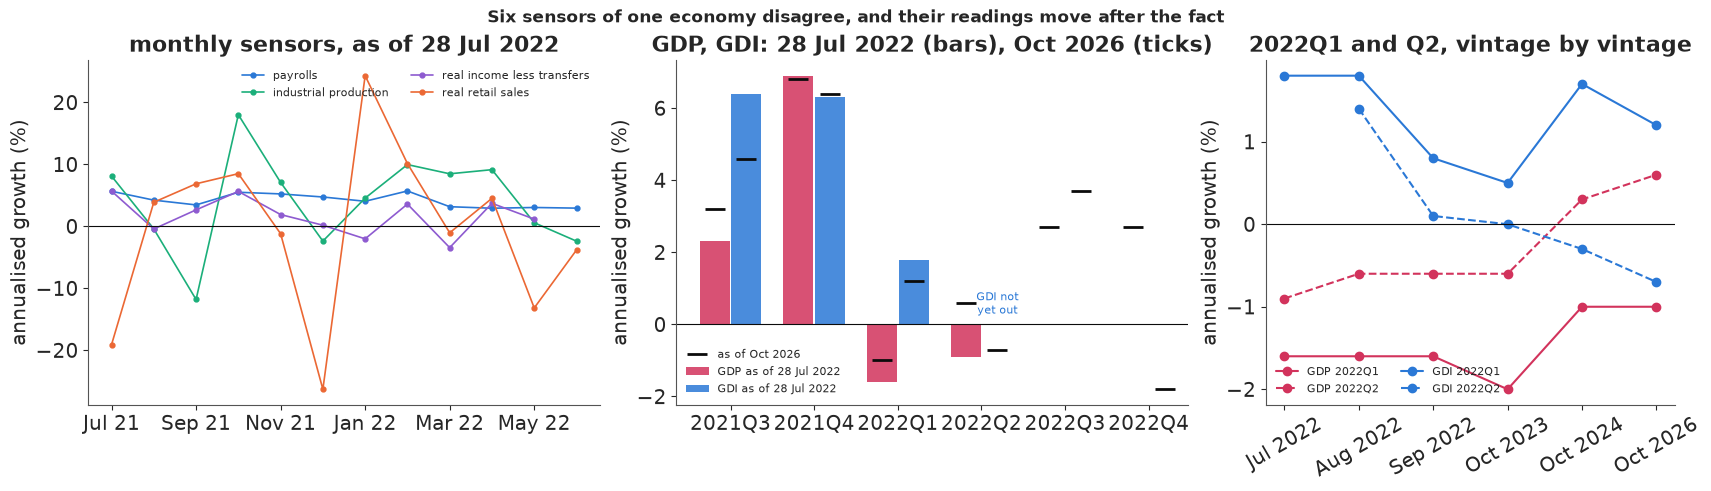

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), width_ratios=[1.25, 1.25, 1])
m0, q0 = SNAP["2022-07-28"]
win = (MONTHS >= "2021-07-01") & (MONTHS <= "2022-06-01")
ax = axes[0]
for s, c in zip(MSER, (BLUE, AQUA, PURPLE, ORANGE)):
    ax.plot(np.arange(win.sum()), m0[s][win], "o-", color=c, lw=1.2, ms=3.5, label=MNAME[s])
ax.axhline(0, color=INK, lw=0.8)
ax.set_xticks(np.arange(0, win.sum(), 2), [d.strftime("%b %y") for d in MONTHS[win][::2]])
ax.set(title="monthly sensors, as of 28 Jul 2022", ylabel="annualised growth (%)")
ax.legend(fontsize=8, ncols=2)
ax = axes[1]
qwin = QUARTERS >= "2021-07-01"
xq = np.arange(qwin.sum())
for j, (s, c) in enumerate((("gdp", RED), ("gdi", BLUE))):
    ax.bar(xq + (j - 0.5) * 0.38, q0[s][qwin], width=0.36, color=c, alpha=0.85,
           label=f"{s.upper()} as of 28 Jul 2022")
    ax.plot(xq + (j - 0.5) * 0.38, q26[s][qwin], "_", color=INK, ms=14, mew=2,
            label="as of Oct 2026" if j == 0 else None)
ax.axhline(0, color=INK, lw=0.8)
ax.set_xticks(xq, [f"{d.year}Q{(d.month - 1) // 3 + 1}" for d in QUARTERS[qwin]])
ax.set(title="GDP, GDI: 28 Jul 2022 (bars), Oct 2026 (ticks)", ylabel="annualised growth (%)")
ax.text(xq[Q2 - np.flatnonzero(qwin)[0]] + 0.19, 0.3, "GDI not\nyet out", ha="center", fontsize=8, color=BLUE)
ax.legend(fontsize=8)
ax = axes[2]
for s, c in (("GDP", RED), ("GDI", BLUE)):
    for qq, ls in (("Q1", "-"), ("Q2", "--")):
        ax.plot(np.arange(len(VINTAGES)), tab_a[f"{s} {qq}"].to_numpy(), ls, marker="o", color=c,
                label=f"{s} 2022{qq}")
ax.axhline(0, color=INK, lw=0.8)
ax.set_xticks(np.arange(len(VINTAGES)), [VLABEL[v] for v in VINTAGES], rotation=30)
ax.set(title="2022Q1 and Q2, vintage by vintage", ylabel="annualised growth (%)")
ax.legend(fontsize=8, ncols=2)
fig.suptitle("Six sensors of one economy disagree, and their readings move after the fact", fontsize=12);

### How noisy is a fresh GDP print?

A number that has just been published will be revised; one that has been through several annual
updates mostly will not. For the 22 quarters 2014Q3-2019Q4 we have the first published growth rate and
the value in the October 2026 vintage. Their difference measures the **revision noise** of a fresh
print, and we will add that much extra variance to every **fresh** GDP or GDI reading. The rule for
"fresh" is deliberately simple: a quarter is fresh at a vintage if the vintage falls less than 245 days
after the quarter's first day, that is, within about five months of the quarter's end. For 2022Q1 that
switch happens between the August and September 2022 vintages, which roughly coincides with the annual
update of 29 September 2022. It is cruder elsewhere: in the July and August 2022 vintages it counts
2021Q3 and 2021Q4 as mature, though neither had yet been through an annual update, and it treats a
quarter as fully mature after one update, though 2022Q1 went on to move from -1.6 to -2.0 and then to
-1.0 in later revisions.

Three more simplifications. The revision size is measured with hindsight, against the October 2026
vintage, which a forecaster in July 2022 could not have done (calibrating against the latest vintage
before each replay date would remove that look-ahead). GDP's revisions also have a mean: on average
they went *up*, by about half a point. We fold that into the variance by using the root mean square
rather than modelling it as a bias, which would have pushed fresh negative prints up further. And we
treat the revision variance as known, though 22 quarters pin a standard deviation down only to about
±15%.

In [5]:
first = raw[~raw.vintage.isin(VINTAGES)]
TAU = {}
for s in ("gdp", "gdi"):
    f = first[first.series == s].set_index("date")["value"]
    latest = raw[(raw.series == s) & (raw.vintage == "2026-10-01")].set_index("date")["value"].reindex(f.index)
    rev = latest - f
    TAU[s] = float(np.sqrt(np.mean(rev**2)))
    print(f"{s.upper()}: {len(rev)} quarters, revision first -> Oct 2026: mean {rev.mean():+.2f}, "
          f"sd {rev.std():.2f}, root mean square {TAU[s]:.2f} percentage points; "
          f"largest {rev.abs().max():.1f}")


def fresh_flags(vintage):
    return ((pd.Timestamp(vintage) - QUARTERS).days < 245).astype(float)

GDP: 22 quarters, revision first -> Oct 2026: mean +0.46, sd 1.38, root mean square 1.42 percentage points; largest 3.4
GDI: 22 quarters, revision first -> Oct 2026: mean +0.20, sd 1.49, root mean square 1.46 percentage points; largest 3.4


A fresh GDP growth rate moves by about 1.4 points on its way to the current vintage, GDI by about 1.5.
That is as large as a typical quarter's growth, and on its own it says that -1.6 and -0.9 were weak
evidence of falling output. How weak depends on everything else we know - which is what the model is for.

## B. One economy, many sensors

### The latent path

Let $g_t$ be the annualised growth of US output in month $t$, $t = 1, \dots, 132$ (January 2012 to
December 2022). Nobody observes it. We give it the simplest dynamics that can work, a stationary AR(1)
around a mean:

$$g_t - \mu = \phi\,(g_{t-1} - \mu) + s\,\varepsilon_t, \qquad \varepsilon_t \sim \mathcal N(0, 1),$$

with $\mu \sim \mathcal N(2, 1)$ (long-run US growth has been around 2% a year), $\phi \sim
\mathrm{Beta}(2, 2)$ and $s \sim \mathrm{LogNormal}(\log 2.5, 0.5)$.

### Quarterly sensors: GDP and GDI

A quarterly growth rate compares the average *level* of output in two quarters. Writing quarter levels
as averages of three monthly log levels and expanding the difference gives the triangle weights of
Mariano & Murasawa (2003): the annualised growth of quarter $q$ whose last month is $t$ is

$$\gamma_q = \tfrac19\left(g_t + 2g_{t-1} + 3g_{t-2} + 2g_{t-3} + g_{t-4}\right),$$

a weighted average of five monthly growth rates, two of them from the previous quarter. Collect the
weights in a $43 \times 132$ matrix $A$, so $\gamma = Ag$. GDP and GDI both measure $\gamma$:

$$\begin{pmatrix} y^{\rm GDP}_q \\ y^{\rm GDI}_q \end{pmatrix} \sim \mathcal N\!\left(
\begin{pmatrix} \gamma_q \\ \gamma_q \end{pmatrix},
\begin{pmatrix} \sigma_P^2 + \tau_P^2 f_q & \rho\,\sigma_P\sigma_I \\ \rho\,\sigma_P\sigma_I & \sigma_I^2 + \tau_I^2 f_q\end{pmatrix}\right),$$

where $f_q = 1$ for a fresh print. Both load on $\gamma_q$ with coefficient one: that fixes the scale of
$g$. Their mature errors may be correlated, $\rho$ (they share source data, and Aruoba et al. (2016) found the
correlation matters and is hard to pin down). Priors: $\sigma_P, \sigma_I \sim \mathrm{LogNormal}(0,
0.5)$ (median 1 point), $(\rho + 1)/2 \sim \mathrm{Beta}(2, 2)$.

### Monthly sensors

Each monthly indicator $k$ is an affine, noisy reading of the same month's output growth,

$$x_{k,t} = a_k + \lambda_k g_t + u_{k,t}, \qquad u_{k,t} = \psi_k u_{k,t-1} + \sigma_k \eta_{k,t},$$

with its own intercept $a_k$ (payrolls grow slower than output because productivity grows), loading
$\lambda_k > 0$ and an error that may persist from month to month ($\psi_k$). The first naive model
will set $\psi_k = 0$. Priors: $a_k \sim \mathcal N(0, 3)$, $\lambda_k \sim \mathrm{LogNormal}(0, 0.75)$,
$\sigma_k \sim \mathrm{LogNormal}(\log 3, 1)$, $\psi_k \sim \mathrm U(-0.99, 0.99)$.

### The ragged edge costs nothing

A reading that does not exist - GDI for 2022Q2 on 28 July, real income for June, a masked pandemic
month - is simply left out of the likelihood. There is nothing to impute: the latent path is defined
for every month, and each sensor contributes where it has reported. "GDP alone" is the same model with
every other sensor switched off, and "as of 28 July 2022" is the same model with the readings published
after that date switched off.

### Integrating the path out

Sampling 132 latent months jointly with the sensor parameters works, but the posterior has ridges (a
smoother economy versus more persistent sensor errors) that cost NUTS thousands of gradient evaluations
per draw. In prototype runs not shown in this notebook, sampling the path directly (centred or
non-centred) gave r-hat of 1.05-1.14 and bulk ESS of 20-90 on the fused model, or hundreds of
divergences; Try it yourself 1 asks for a model where you meet this for yourself.
Given the parameters $\theta$, though, everything is linear and Gaussian, so the path can be integrated
out exactly - the same thing a Kalman filter does (E13), done in one solve.

Write every reading, after a transformation with unit Jacobian, as $y_i = c_i + h_i^\top g + e_i$ with
independent $e_i \sim \mathcal N(0, v_i)$: a monthly reading with AR(1) error becomes the
quasi-difference $x_{k,t} - \psi_k x_{k,t-1} = a_k(1 - \psi_k) + \lambda_k(g_t - \psi_k g_{t-1}) +
\sigma_k\eta_{k,t}$ (the first reading after a gap keeps its stationary variance), and GDI becomes its
conditional distribution given GDP. With the AR(1) prior precision $Q_0$ (tridiagonal), the posterior
precision of the path and the marginal likelihood are

$$Q = Q_0 + \sum_i \frac{h_i h_i^\top}{v_i}, \qquad b = \sum_i \frac{h_i r_i}{v_i}, \qquad
\log p(y \mid \theta) = -\tfrac12\Bigl[n\log 2\pi + \sum_i \log v_i - \log|Q_0| + \log|Q| + \sum_i
\frac{r_i^2}{v_i} - b^\top Q^{-1} b\Bigr],$$

with $r_i = y_i - c_i - \mu\,h_i^\top \mathbf 1$ (matrix determinant lemma plus Woodbury). Each monthly
sensor adds a **tridiagonal** band to $Q$ and the quarterly sensors a band five months wide, so $Q$ is a
narrow-band $132 \times 132$ matrix; one Cholesky factor gives everything. This is the "precision-based"
state-space method of Rue & Held (2005) and Chan & Jeliazkov (2009). After sampling $\theta$, we draw the
path from $g \mid y, \theta \sim \mathcal N(\mu\mathbf 1 + Q^{-1}b,\; Q^{-1})$, one exact draw per
posterior draw.

The function below is written once for NumPy and PyTensor (the `xp` argument): the model uses it for the
likelihood, NumPy for the path draws and the checks.

In [6]:
A = np.zeros((NQ, T))
for j, qs in enumerate(QUARTERS):
    t_last = MONTHS.get_loc(qs) + 2
    A[j, t_last - np.arange(5)] = np.array([1, 2, 3, 2, 1]) / 9
EYE, SUP = np.eye(T), np.eye(T, k=1)
ALL = ("gdp", "gdi") + tuple(MSER)


def ar1_precision(phi, s):
    """Precision of a stationary AR(1) path with innovation sd s (tridiagonal)."""
    inner = np.r_[0.0, np.ones(T - 2), 0.0]
    return (EYE + phi**2 * np.diag(inner) - phi * (SUP + SUP.T)) / s**2


def sensor_algebra(p, d, xp):
    """Q_data, b, sum r^2/v, sum log v, n for parameters p and readings d (NumPy or PyTensor)."""
    mu, sp, si = p["mu"], p["sig_gdp"], p["sig_gdi"]
    vp = sp**2 + TAU["gdp"] ** 2 * d["fresh"]
    vi = si**2 + TAU["gdi"] ** 2 * d["fresh"]
    cov = p["rho"] * sp * si
    kap = cov / vp                                   # GDI given GDP: regression coefficient
    vic = vi - cov**2 / vp                           # ... and conditional variance
    rp = d["gdp_y"] - mu
    ri = d["gdi_y"] - kap * d["gdp_y"] - (1 - kap) * mu
    wq = d["gdp_ok"] / vp + d["gdi_ok"] * (1 - kap) ** 2 / vic
    Q = A.T @ (wq[:, None] * A)
    b = A.T @ (d["gdp_ok"] * rp / vp + d["gdi_ok"] * (1 - kap) * ri / vic)
    quad = xp.sum(d["gdp_ok"] * rp**2 / vp + d["gdi_ok"] * ri**2 / vic)
    logv = xp.sum(d["gdp_ok"] * xp.log(vp) + d["gdi_ok"] * xp.log(vic))
    n = xp.sum(d["gdp_ok"]) + xp.sum(d["gdi_ok"])
    diag, off = 0 * mu + np.zeros(T), 0 * mu + np.zeros(T - 1)
    for k in MSER:
        ic, i0, x, xl = d[f"ic_{k}"], d[f"i0_{k}"], d[f"x_{k}"], d[f"xl_{k}"]
        a, lam, sig = p[f"a_{k}"], p[f"lam_{k}"], p[f"sig_{k}"]
        psi = d["use_ar"] * p[f"psi_{k}"]
        w, w0 = lam**2 / sig**2, lam**2 * (1 - psi**2) / sig**2
        rc = ic * (x - psi * xl - (a + lam * mu) * (1 - psi))      # quasi-differenced readings
        r0 = i0 * (x - a - lam * mu)                               # first reading of a run
        diag = diag + w * ic + w * psi**2 * xp.concatenate([ic[1:], np.zeros(1)]) + w0 * i0
        off = off - w * psi * ic[1:]
        b = b + lam / sig**2 * (rc - psi * xp.concatenate([rc[1:], np.zeros(1)])) + w0 / lam * r0
        quad = quad + (xp.sum(rc**2) + (1 - psi**2) * xp.sum(r0**2)) / sig**2
        logv = logv + xp.sum(ic) * xp.log(sig**2) + xp.sum(i0) * xp.log(sig**2 / (1 - psi**2))
        n = n + xp.sum(ic) + xp.sum(i0)
    off_full = xp.concatenate([off, np.zeros(1)])
    Q = Q + diag[:, None] * EYE + off_full[:, None] * SUP + off_full[None, :] * SUP.T
    return Q, b, quad, logv, n


def readings(vintage, sensors=ALL, use_ar=1.0, rho=None, hide=()):
    """The data arrays for one fit: which readings exist at this vintage, for these sensors."""
    m, q = SNAP[vintage]
    d = {"fresh": fresh_flags(vintage)}
    gdp_ok = ~np.isnan(q["gdp"]) & ("gdp" in sensors)
    for qq in hide:                                  # readings held out on purpose (part G)
        gdp_ok[QUARTERS.get_loc(qq)] = False
    gdi_ok = ~np.isnan(q["gdi"]) & gdp_ok & ("gdi" in sensors)
    d |= {"gdp_y": np.nan_to_num(q["gdp"]), "gdp_ok": gdp_ok.astype(float),
          "gdi_y": np.nan_to_num(q["gdi"]), "gdi_ok": gdi_ok.astype(float)}
    for k in MSER:
        x = m[k]
        ok = ~np.isnan(x) & (k in sensors)
        ic = np.r_[False, ok[:-1]] & ok
        d |= {f"x_{k}": np.nan_to_num(x), f"xl_{k}": np.r_[0.0, np.nan_to_num(x[:-1])],
              f"ic_{k}": ic.astype(float), f"i0_{k}": (ok & ~ic).astype(float)}
    d |= {"use_ar": np.array(use_ar), "rho_free": np.array(float(rho is None)),
          "rho_value": np.array(0.0 if rho is None else float(rho))}
    return d

Before trusting 40 lines of algebra, we check them. For one parameter point (random sensor
parameters) we compute the log-likelihood of the 28 July 2022 data two ways: with the banded formula
above, and by brute force - stacking every raw reading into one vector and evaluating a multivariate
normal with the full covariance $M\Sigma_g M^\top + \Sigma_e$ (AR(1) blocks within each run of a monthly
sensor, 2 × 2 GDP-GDI blocks per quarter).

In [7]:
def loglik_banded(p, d):
    Qd, b, quad, logv, n = sensor_algebra(p, d, np)
    L = np.linalg.cholesky(ar1_precision(p["phi"], p["s"]) + Qd)
    w = np.linalg.solve(L, b)
    logdet_q0 = -2 * T * np.log(p["s"]) + np.log(1 - p["phi"] ** 2)
    return -0.5 * (n * np.log(2 * np.pi) + logv - logdet_q0 + 2 * np.log(np.diag(L)).sum() + quad - w @ w)


def loglik_brute(p, d):
    rows, M, mean = [], [], []
    for s in ("gdp", "gdi"):
        for j in np.flatnonzero(d[f"{s}_ok"]):
            rows.append((s, j)); M.append(A[j]); mean.append(p["mu"])
    for k in MSER:
        for t in np.flatnonzero(d[f"ic_{k}"] + d[f"i0_{k}"]):
            rows.append((k, t)); M.append(p[f"lam_{k}"] * EYE[t])
            mean.append(p[f"a_{k}"] + p[f"lam_{k}"] * p["mu"])
    M, mean = np.array(M), np.array(mean)
    y = np.array([d[f"{s}_y"][j] if s in ("gdp", "gdi") else d[f"x_{s}"][j] for s, j in rows])
    S = M @ np.linalg.inv(ar1_precision(p["phi"], p["s"])) @ M.T
    run = {k: np.cumsum(d[f"i0_{k}"]) for k in MSER}               # run id of each month
    for i, (si, ti) in enumerate(rows):
        for j, (sj, tj) in enumerate(rows):
            if si in ("gdp", "gdi") and sj in ("gdp", "gdi") and ti == tj:
                vp = p["sig_gdp"] ** 2 + TAU["gdp"] ** 2 * d["fresh"][ti]
                vi = p["sig_gdi"] ** 2 + TAU["gdi"] ** 2 * d["fresh"][ti]
                S[i, j] += vp if si == sj == "gdp" else vi if si == sj == "gdi" else p["rho"] * p["sig_gdp"] * p["sig_gdi"]
            elif si == sj and si in MSER and run[si][ti] == run[si][tj]:
                psi = d["use_ar"] * p[f"psi_{si}"]
                S[i, j] += p[f"sig_{si}"] ** 2 / (1 - psi**2) * psi ** abs(ti - tj)
    return stats.multivariate_normal(mean, S).logpdf(y), len(y)


p_test = {"mu": 2.1, "phi": 0.4, "s": 2.0, "sig_gdp": 1.2, "sig_gdi": 1.6, "rho": 0.35}
for k in MSER:
    p_test |= {f"a_{k}": rng.normal(), f"lam_{k}": rng.uniform(0.5, 1.5), f"sig_{k}": rng.uniform(0.5, 6),
               f"psi_{k}": rng.uniform(-0.5, 0.95)}
d_test = readings("2022-07-28")
brute, n_read = loglik_brute(p_test, d_test)
print(f"{n_read} readings on 28 July 2022; log-likelihood banded {loglik_banded(p_test, d_test):.6f}, "
      f"brute force {brute:.6f}")

508 readings on 28 July 2022; log-likelihood banded -4299.607948, brute force -4299.607948


The two agree to all printed digits on 508 readings, so the banded algebra (quasi-differencing, the
conditional GDI term, the gaps) is the multivariate normal it claims to be.

### The model, compiled once

Every quantity that changes between fits - the readings, which of them exist, whether sensor errors
persist, whether $\rho$ is free - is a `pm.Data` container. We compile the model once with nutpie and
swap the data for each of the fits that follow (`compiled.with_data`), so a new vintage or a dropped
sensor costs a sampling run but no new compilation. A parameter of a switched-off sensor is still
sampled, from its prior; it affects nothing.

In [8]:
def build_model(d0):
    with pm.Model() as model:
        D = {k: pm.Data(k, v) for k, v in d0.items()}
        p = {"mu": pm.Normal("mu", 2.0, 1.0), "phi": pm.Beta("phi", 2.0, 2.0),
             "s": pm.LogNormal("s", np.log(2.5), 0.5),
             "sig_gdp": pm.LogNormal("sig_gdp", 0.0, 0.5), "sig_gdi": pm.LogNormal("sig_gdi", 0.0, 0.5)}
        r = pm.Beta("r", 2.0, 2.0)
        p["rho"] = pm.Deterministic("rho", D["rho_free"] * (2 * r - 1) + (1 - D["rho_free"]) * D["rho_value"])
        for k in MSER:
            p[f"a_{k}"] = pm.Normal(f"a_{k}", 0.0, 3.0)
            p[f"lam_{k}"] = pm.LogNormal(f"lam_{k}", 0.0, 0.75)
            p[f"sig_{k}"] = pm.LogNormal(f"sig_{k}", np.log(3.0), 1.0)
            p[f"psi_{k}"] = pm.Uniform(f"psi_{k}", -0.99, 0.99)
        Qd, b, quad, logv, n = sensor_algebra(p, D, pt)
        L = pt.linalg.cholesky(ar1_precision(p["phi"], p["s"]) + Qd)
        w = pt.linalg.solve_triangular(L, b, lower=True)
        logdet_q0 = -2 * T * pt.log(p["s"]) + pt.log(1 - p["phi"] ** 2)
        pm.Potential("loglik", -0.5 * (n * np.log(2 * np.pi) + logv - logdet_q0
                                       + 2 * pt.sum(pt.log(pt.diag(L))) + quad - pt.sum(w**2)))
    return model


model = build_model(readings("2022-07-28"))
t0 = time.time()
COMPILED = nutpie.compile_pymc_model(model)
print(f"compiled in {time.time() - t0:.0f} s; free parameters: {len(model.free_RVs)}")

compiled in 29 s; free parameters: 22


### Prior predictive check

Before any data: what does the prior say about quarterly output growth, about GDP prints, and about
our question? `pm.sample_prior_predictive` gives the parameter draws (the `Potential` has no generative
form, so it is skipped); we simulate paths and GDP prints from them in NumPy.

prior sd of quarterly output growth: median over draws 2.09 (90% of draws between 0.77 and 6.22); sd of GDP prints 2012-2019: 1.47
prior P(2022Q1 < 0 and 2022Q2 < 0) = 0.12; prior P(output fell over the half year, mean of Q1 and Q2 < 0) = 0.19


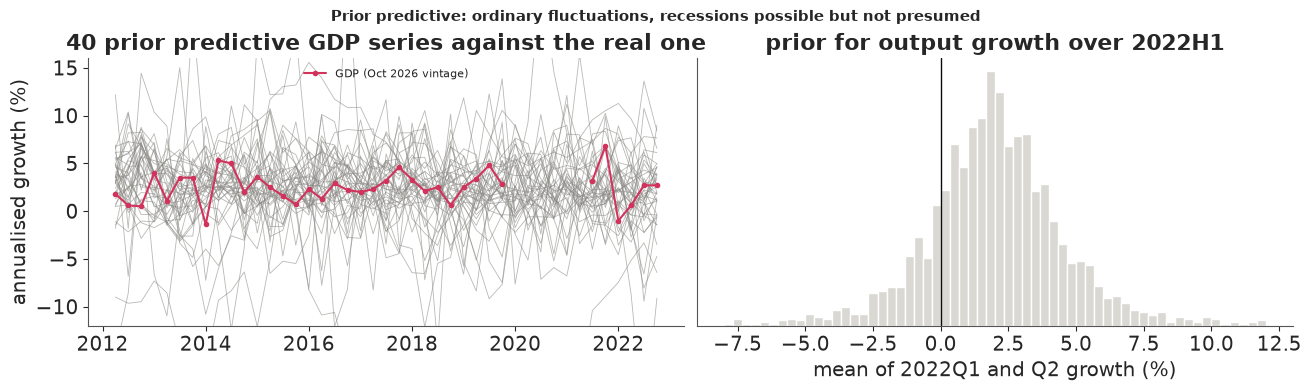

In [9]:
def simulate_paths(pp, rng, n_t=T):
    """Stationary AR(1) paths for arrays of mu, phi, s."""
    mu, phi, s = (np.asarray(pp[k])[:, None] for k in ("mu", "phi", "s"))
    eps = rng.standard_normal((len(mu), n_t))
    g = np.empty((len(mu), n_t))
    g[:, 0] = mu[:, 0] + s[:, 0] / np.sqrt(1 - phi[:, 0] ** 2) * eps[:, 0]
    for t in range(1, n_t):
        g[:, t] = mu[:, 0] + phi[:, 0] * (g[:, t - 1] - mu[:, 0]) + s[:, 0] * eps[:, t]
    return g


prior = pm.sample_prior_predictive(draws=2000, model=model, random_seed=RANDOM_SEED)
pp = {k: prior.prior[k].values.ravel() for k in ("mu", "phi", "s", "sig_gdp")}
g_prior = simulate_paths(pp, rng)
gq_prior = g_prior @ A.T
gdp_prior = gq_prior + pp["sig_gdp"][:, None] * rng.standard_normal(gq_prior.shape)
obs_gdp = q26["gdp"][~np.isnan(q26["gdp"])]
print(f"prior sd of quarterly output growth: median over draws {np.median(gq_prior.std(axis=1)):.2f} "
      f"(90% of draws between {np.quantile(gq_prior.std(axis=1), 0.05):.2f} and "
      f"{np.quantile(gq_prior.std(axis=1), 0.95):.2f}); sd of GDP prints 2012-2019: {np.std(obs_gdp[:31]):.2f}")
print(f"prior P(2022Q1 < 0 and 2022Q2 < 0) = {np.mean((gq_prior[:, Q1] < 0) & (gq_prior[:, Q2] < 0)):.2f}; "
      f"prior P(output fell over the half year, mean of Q1 and Q2 < 0) = "
      f"{np.mean(gq_prior[:, [Q1, Q2]].mean(axis=1) < 0):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
for i in range(40):
    ax.plot(QUARTERS, gdp_prior[i], color=MUTED, lw=0.6, alpha=0.6)
ax.plot(QUARTERS, q26["gdp"], "o-", color=RED, ms=3, lw=1.5, label="GDP (Oct 2026 vintage)")
ax.set(title="40 prior predictive GDP series against the real one", ylabel="annualised growth (%)", ylim=(-12, 16))
ax.legend(fontsize=8)
ax = axes[1]
bins = np.linspace(-8, 12, 61)
ax.hist(gq_prior[:, [Q1, Q2]].mean(axis=1), bins=bins, color=LIGHT, edgecolor="white", density=True)
ax.axvline(0, color=INK, lw=1)
ax.set(title="prior for output growth over 2022H1", xlabel="mean of 2022Q1 and Q2 growth (%)", yticks=[])
fig.suptitle("Prior predictive: ordinary fluctuations, recessions possible but not presumed", fontsize=11);

The prior puts quarterly output growth on roughly the scale of real GDP growth (a typical prior economy has
a quarterly sd of 2.1 points against 1.5 for GDP in 2012-2019), allows much wilder ones, and does not
rule a contraction in or out: about one chance in five that output fell over the first half of 2022, one
in eight that both quarters were negative. These numbers are the baseline against which every posterior
below should be read. Two quantities will carry the question from now on: **P(both quarters negative)**,
the two-quarter rule applied to *latent* output, and **P(H1 contraction)**, the probability that output
in 2022Q2 was below 2021Q4 (the mean of the two quarterly growth rates is negative).

## C. GDP alone, 28 July 2022

The fitting machinery: swap in the readings, sample with nutpie (4 chains, 400 warm-up and 1,000 kept
draws each, the `pm.sample` defaults), then draw one exact latent path per posterior draw for 1,000 of
them.

In [10]:
ACTIVE_BASE = ["mu", "phi", "s", "sig_gdp"]


def active_vars(d):
    names = list(ACTIVE_BASE)
    if d["gdi_ok"].sum() > 0:
        names += ["sig_gdi"] + (["rho"] if d["rho_free"] > 0 else [])
    for k in MSER:
        if d[f"ic_{k}"].sum() > 0:
            names += [f"a_{k}", f"lam_{k}", f"sig_{k}"] + ([f"psi_{k}"] if d["use_ar"] > 0 else [])
    return names


def draw_paths(idata, d, n=1000, seed=0):
    """Exact draws of the latent path, one per posterior draw (n of them), plus those draws' parameters."""
    post = az.extract(idata, num_samples=n, random_seed=seed)
    P = {k: post[k].values for k in post.data_vars if post[k].ndim == 1}
    r = np.random.default_rng(seed)
    g = np.empty((n, T))
    for i in range(n):
        p = {k: v[i] for k, v in P.items()}
        Qd, b, _, _, _ = sensor_algebra(p, d, np)
        Qp = ar1_precision(p["phi"], p["s"]) + Qd
        L = np.linalg.cholesky(Qp)
        mean = np.linalg.solve(L.T, np.linalg.solve(L, b))
        g[i] = p["mu"] + mean + np.linalg.solve(L.T, r.standard_normal(T))
    return g, P


FITS = {}


def fit(key, vintage, seed, **kw):
    d = readings(vintage, **kw)
    t0 = time.time()
    idata = nutpie.sample(COMPILED.with_data(**d), chains=4, tune=400, draws=1000, seed=seed,
                          progress_bar=False, save_warmup=False)
    secs = time.time() - t0
    g, P = draw_paths(idata, d, seed=seed)
    gq = g @ A.T
    names = active_vars(d)
    rhat = max(float(az.rhat(idata.posterior[v]).max()) for v in names)
    ess = min(float(az.ess(idata.posterior[v]).min()) for v in names)
    div = int(idata.sample_stats["diverging"].sum())
    FITS[key] = {"idata": idata, "d": d, "g": g, "P": P, "gq": gq, "vintage": vintage,
                 "both": np.mean((gq[:, Q1] < 0) & (gq[:, Q2] < 0)),
                 "h1": np.mean(gq[:, [Q1, Q2]].mean(axis=1) < 0)}
    label = key if key.endswith(VLABEL[vintage]) else f"{key}, {VLABEL[vintage]}"
    print(f"{label:<28} {secs:3.0f} s, divergences {div}, max r_hat {rhat:.3f}, "
          f"min bulk ESS {ess:.0f} | 2022Q1 {gq[:, Q1].mean():+.2f} ± {gq[:, Q1].std():.2f}, "
          f"2022Q2 {gq[:, Q2].mean():+.2f} ± {gq[:, Q2].std():.2f} | P(both < 0) {FITS[key]['both']:.3f}, "
          f"P(H1 contraction) {FITS[key]['h1']:.3f}")
    return FITS[key]


f_gdp = fit("GDP alone", "2022-07-28", seed=RANDOM_SEED, sensors=("gdp",))
print(az.summary(f_gdp["idata"], var_names=ACTIVE_BASE, round_to=3).to_string())

GDP alone, Jul 2022            6 s, divergences 0, max r_hat 1.001, min bulk ESS 2560 | 2022Q1 +1.38 ± 1.05, 2022Q2 +1.00 ± 1.13 | P(both < 0) 0.047, P(H1 contraction) 0.104
          mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
mu       2.212  0.321     1.699     2.733  9397.972  3038.865  1.001      0.003    0.006
phi      0.296  0.152     0.078     0.559  5168.182  2982.310  1.001      0.002    0.002
s        1.890  0.655     0.931     2.982  2560.122  2788.168  1.001      0.013    0.008
sig_gdp  1.139  0.334     0.577     1.649  2732.097  2128.925  1.001      0.006    0.005


The sampler is healthy (no divergences, r-hat 1.00, thousands of effective draws: integrating the path
out removed the ridges). The answer may surprise anyone who took the two negative prints at face value:
with GDP alone, the posterior mean of latent growth is about +1.4 in the first quarter and +1 in the
second, and **P(H1 contraction) is about 0.1** - *lower* than the prior's 0.19. Two things pull the
estimate up from the prints. First, the history says growth averages about 2.2% ($\mu$) and that much of
the quarter-to-quarter wobble in GDP is measurement noise. Second, both prints were fresh, so each carries
1.4 points of revision noise on top of $\sigma_P$. A reading of -1.6 with a standard deviation near 1.8
does not move a path that hovers around +2 very far.

What can one sensor learn about its own noise? Very little: GDP's variance is the sum of the economy's
variance and the measurement noise, and a single series cannot split them except through the AR
structure (smooth latent path, white noise).

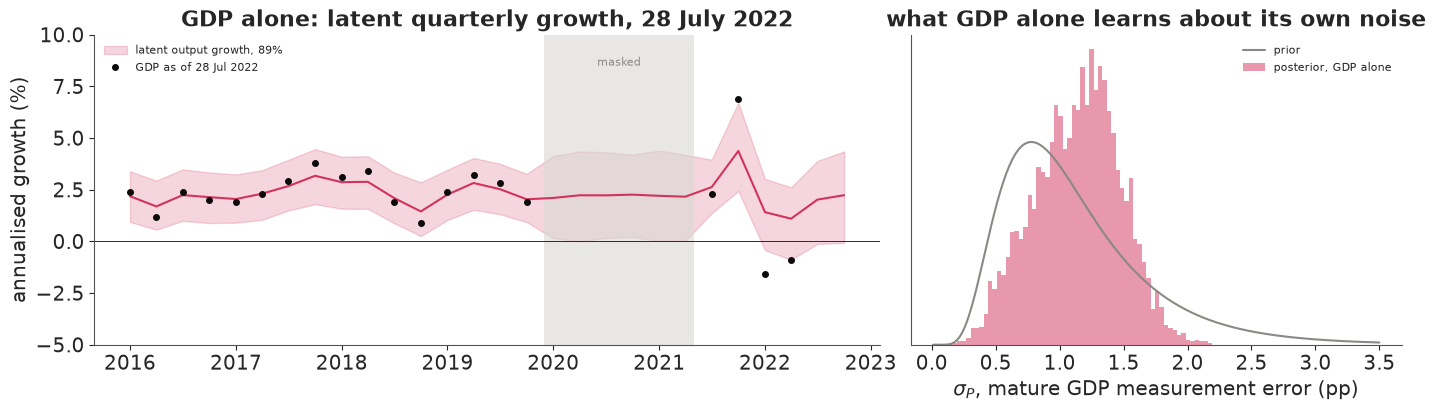

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), width_ratios=[1.6, 1])
ax = axes[0]
gq = f_gdp["gq"]
lo, med, hi = np.quantile(gq, [0.055, 0.5, 0.945], axis=0)
qwin = QUARTERS >= "2016-01-01"
ax.fill_between(QUARTERS[qwin], lo[qwin], hi[qwin], color=RED, alpha=0.2, label="latent output growth, 89%")
ax.plot(QUARTERS[qwin], med[qwin], color=RED, lw=1.5)
ax.plot(QUARTERS[qwin], q0["gdp"][qwin], "o", color=INK, ms=4, label="GDP as of 28 Jul 2022")
ax.axhline(0, color=INK, lw=0.6)
ax.axvspan(pd.Timestamp("2019-12-01"), pd.Timestamp("2021-05-01"), color=LIGHT, alpha=0.6, lw=0)
ax.text(pd.Timestamp("2020-08-15"), 8.5, "masked", ha="center", fontsize=8, color=MUTED)
ax.set(ylim=(-5, 10), ylabel="annualised growth (%)", title="GDP alone: latent quarterly growth, 28 July 2022")
ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
xs = np.linspace(0.01, 3.5, 300)
ax.plot(xs, stats.lognorm(0.5, scale=1.0).pdf(xs), color=MUTED, lw=1.5, label="prior")
ax.hist(f_gdp["idata"].posterior["sig_gdp"].values.ravel(), bins=60, density=True, color=RED, alpha=0.5,
        label="posterior, GDP alone")
ax.set(xlabel=r"$\sigma_P$, mature GDP measurement error (pp)", yticks=[],
       title="what GDP alone learns about its own noise")
ax.legend(fontsize=8);

The latent band is wide - about ±1.2 points around each quarter before the pandemic and ±1.7 in 2022 -
and in the masked quarters, where no sensor reports, the path simply returns to the long-run mean. The
posterior for $\sigma_P$ (mean 1.1, sd 0.33) has moved only modestly from the prior (median 1, sd about
0.6), so the GDP-alone answer leans on that prior: how far the latent path follows the two negative
prints depends on how noisy we believed GDP to be before seeing it. Fusion's first job is to let other
sensors settle that instead.

## D. Fusion, and a sensor that counts twice

### Failure: errors that do not persist

The naive fused model takes all six sensors and treats each monthly sensor's error as independent from
month to month ($\psi_k = 0$, switched off through the `use_ar` data flag).

In [12]:
f_iid = fit("fused, iid errors", "2022-07-28", seed=RANDOM_SEED + 1, use_ar=0.0)
print(az.summary(f_iid["idata"], var_names=["mu", "phi", "s", "sig_gdp", "sig_gdi", "rho", "lam_payrolls",
                                            "sig_payrolls", "a_payrolls"], round_to=3).to_string())

fused, iid errors, Jul 2022   12 s, divergences 0, max r_hat 1.003, min bulk ESS 1472 | 2022Q1 +4.78 ± 0.55, 2022Q2 +3.69 ± 0.42 | P(both < 0) 0.000, P(H1 contraction) 0.000
               mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
mu            2.459  0.410     1.820     3.103  3298.873  2769.165  1.000      0.007    0.008
phi           0.862  0.068     0.738     0.952  2692.634  2646.153  1.001      0.001    0.001
s             0.526  0.134     0.343     0.762  1759.355  2269.849  1.002      0.003    0.002
sig_gdp       1.536  0.212     1.237     1.902  4984.688  3113.874  1.000      0.003    0.004
sig_gdi       1.836  0.227     1.511     2.230  4252.843  2605.180  1.001      0.004    0.004
rho           0.186  0.162    -0.083     0.439  4721.730  3073.295  1.001      0.002    0.003
lam_payrolls  0.987  0.196     0.716     1.322  1471.954  1738.330  1.001      0.005    0.004
sig_payrolls  0.569  0.079     0.439     0.691  3188.640  2270.317  1.002 

The probability of a contraction has gone to zero, and the estimate of first-quarter growth is near
+4.8 with a standard deviation around 0.55: the model is *sure* the economy was booming. Look at how it
got there. The latent path became smooth (monthly persistence $\phi \approx 0.86$, innovation sd $s
\approx 0.5$, against 0.3 and 1.9 with GDP alone), the payroll loading is about 1 and the payroll noise
only about 0.6 points: the model has decided that **the economy is payrolls**. Payroll growth is very
smooth from month to month; with independent errors, the only way the model can explain a smooth
sensor is a smooth economy that the sensor reads almost perfectly. Payrolls grew at 3.6% in the first half
of 2022, so the economy must have grown fast.

Can a check see this? If the model is right, a sensor's standardised innovations - here simply
$(x_{k,t} - a_k - \lambda_k g_t)/\sigma_k$ - are white noise. For each posterior draw (with its own
latent path) we compute their lag-1 autocorrelation and compare it with the same statistic on white noise
of the same length: a posterior predictive check with a realised discrepancy (Gelman, Meng & Stern 1996).
A second, blunter check asks how far the two GDP prints of 2022 sit from each model's latent quarterly
growth, in units of their measurement sd.

In [13]:
def innovation_check(f, k, rng):
    """Lag-1 autocorrelation of standardised innovations: observed vs replicated, per posterior draw."""
    d, P, g = f["d"], f["P"], f["g"]
    ok = (d[f"ic_{k}"] > 0)
    x, xl = d[f"x_{k}"], d[f"xl_{k}"]
    psi = d["use_ar"] * P[f"psi_{k}"][:, None]
    e = x[None, :] - P[f"a_{k}"][:, None] - P[f"lam_{k}"][:, None] * g
    el = xl[None, :] - P[f"a_{k}"][:, None] - P[f"lam_{k}"][:, None] * np.c_[g[:, :1] * 0, g[:, :-1]]
    innov = (e - psi * el)[:, ok] / P[f"sig_{k}"][:, None]
    rep = rng.standard_normal(innov.shape)

    def ac1(z):
        z = z - z.mean(axis=1, keepdims=True)
        return (z[:, 1:] * z[:, :-1]).sum(axis=1) / (z**2).sum(axis=1)
    return ac1(innov), ac1(rep)


rows = []
for k in MSER:
    obs_ac, rep_ac = innovation_check(f_iid, k, rng)
    rows.append({"sensor": MNAME[k], "observed lag-1 autocorr (mean)": obs_ac.mean(),
                 "replicated (mean)": rep_ac.mean(), "P(replicated > observed)": np.mean(rep_ac > obs_ac)})
print("naive fused model, 28 July 2022:")
print(pd.DataFrame(rows).set_index("sensor").round(3).to_string())


def gdp_z(f, qi):
    """Posterior mean of (GDP print - latent growth) / measurement sd for quarter qi."""
    v = f["P"]["sig_gdp"] ** 2 + TAU["gdp"] ** 2 * f["d"]["fresh"][qi]
    return np.mean((f["d"]["gdp_y"][qi] - f["gq"][:, qi]) / np.sqrt(v))


print("\nGDP prints minus latent growth, in measurement sds:")
for f, lab in ((f_gdp, "GDP alone"), (f_iid, "fused, iid errors")):
    print(f"  {lab:<20} 2022Q1 {gdp_z(f, Q1):+.2f}, 2022Q2 {gdp_z(f, Q2):+.2f}")

naive fused model, 28 July 2022:
                            observed lag-1 autocorr (mean)  replicated (mean)  P(replicated > observed)
sensor                                                                                                 
payrolls                                            -0.055             -0.009                     0.642
industrial production                                0.029             -0.008                     0.343
real income less transfers                          -0.125             -0.014                     0.882
real retail sales                                   -0.246             -0.011                     0.993

GDP prints minus latent growth, in measurement sds:
  GDP alone            2022Q1 -1.62, 2022Q2 -1.02
  fused, iid errors    2022Q1 -3.05, 2022Q2 -2.20


The check flags retail sales clearly (lag-1 autocorrelation about -0.25; 99% of white-noise replicates
are above it): a strong month tends to be followed by a weak one, a sawtooth that independent errors
cannot produce. Real income shows a hint of the same sawtooth (-0.12, with 88% of replicates above it, not
enough to flag on its own). The check does **not** flag payrolls (-0.05, well inside the replicates).
That is the blind spot of a residual check on a latent model: the model has bent the latent path to
payrolls, so payrolls' residuals around that path look like white noise. The evidence is in the other
sensors. Under the naive model the first-quarter GDP print sits about 3 measurement sds below latent
output, against 1.6 for GDP alone; GDP has become an outlier to a path drawn by payrolls.

### Fix: persistent sensor errors

Give every monthly sensor an AR(1) error, $u_{k,t} = \psi_k u_{k,t-1} + \sigma_k\eta_{k,t}$. A persistent
deviation of payrolls from output - a stretch in which hiring runs ahead of output - is now one
slow-moving error, not a dozen independent confirmations that output grew.

In [14]:
f_ar = fit("fused", "2022-07-28", seed=RANDOM_SEED + 2)
print(az.summary(f_ar["idata"], var_names=active_vars(f_ar["d"]), round_to=3).to_string())
rows = []
for k in MSER:
    obs_ac, rep_ac = innovation_check(f_ar, k, rng)
    rows.append({"sensor": MNAME[k], "observed lag-1 autocorr (mean)": obs_ac.mean(),
                 "replicated (mean)": rep_ac.mean(), "P(replicated > observed)": np.mean(rep_ac > obs_ac)})
print("\nfused model with AR(1) sensor errors, 28 July 2022:")
print(pd.DataFrame(rows).set_index("sensor").round(3).to_string())

print(f"GDP print minus latent growth, in measurement sds (fused, AR(1) errors): "
      f"2022Q1 {gdp_z(f_ar, Q1):+.2f}, 2022Q2 {gdp_z(f_ar, Q2):+.2f}")

fused, Jul 2022               11 s, divergences 0, max r_hat 1.003, min bulk ESS 913 | 2022Q1 +3.19 ± 0.60, 2022Q2 +1.24 ± 0.73 | P(both < 0) 0.000, P(H1 contraction) 0.003
                          mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
mu                       2.325  0.264     1.906     2.746  4927.847  2924.546  1.001      0.004    0.004
phi                      0.190  0.100     0.050     0.364  3689.902  2034.217  1.000      0.002    0.002
s                        1.548  0.399     0.962     2.207  1013.834  1137.659  1.002      0.012    0.009
sig_gdp                  1.356  0.194     1.062     1.680  3600.020  2478.367  1.000      0.003    0.004
sig_gdi                  1.820  0.238     1.474     2.238  3280.417  2679.240  1.000      0.004    0.004
rho                      0.126  0.177    -0.160     0.401  2732.161  2143.743  1.001      0.003    0.003
a_payrolls               1.368  0.664     0.368     2.431  1976.241  2092.008  1.001      0.

The payroll error persistence is estimated at $\psi \approx 0.96$ (89% interval 0.90-0.99), far from
the zero the naive model assumed: payrolls' deviation from output is nearly a random walk, so they inform
the model about *changes* in growth, not its level. That estimate sits against the prior's upper edge of
0.99; the cap is what keeps the payroll error stationary, and since the first reading of a run has
variance $\sigma_k^2/(1-\psi_k^2)$, how much the payroll *level* says depends on where that cap is. Their loading halves (to about 0.5) and their
innovation sd drops to about 0.25. Retail sales gets $\psi \approx -0.25$ and real income $-0.10$, the
sawtooth the check found. The latent path is no longer smooth ($\phi \approx 0.2$, $s \approx 1.5$, close
to the GDP-alone values), and the GDP and GDI noise are now learned from the data rather than the prior:
$\sigma_P \approx 1.4$ and $\sigma_I \approx 1.8$ with posterior sds of about 0.2. The innovation check
passes for every sensor, and the first-quarter GDP print is now about 2.5 sds below latent output - still
a large miss, which part G comes back to.

The answer to the question did not change - the contraction probability is still essentially zero - but
its size did: first-quarter growth is now about +3.2 (sd 0.6) instead of +4.8, and second-quarter
growth about +1.2 (sd 0.7) instead of +3.7.

GDP alone     first-half growth: mean +1.19, sd 0.90
fused, iid    first-half growth: mean +4.23, sd 0.46
fused, AR(1)  first-half growth: mean +2.21, sd 0.54


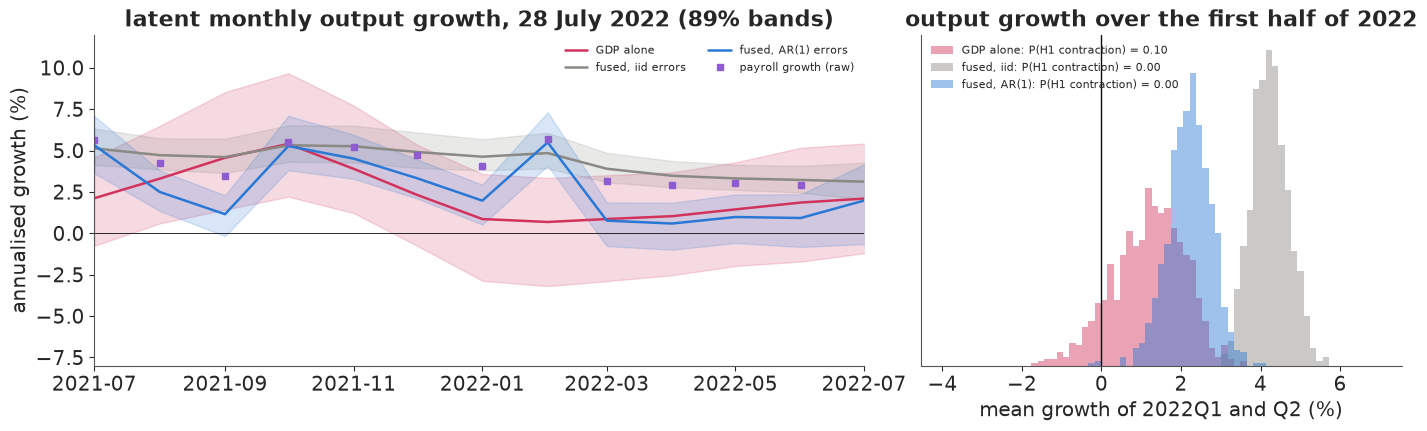

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), width_ratios=[1.6, 1])
ax = axes[0]
mwin = MONTHS >= "2021-07-01"
for f, c, lab in ((f_gdp, RED, "GDP alone"), (f_iid, MUTED, "fused, iid errors"), (f_ar, BLUE, "fused, AR(1) errors")):
    lo, med, hi = np.quantile(f["g"], [0.055, 0.5, 0.945], axis=0)
    ax.fill_between(MONTHS[mwin], lo[mwin], hi[mwin], color=c, alpha=0.18)
    ax.plot(MONTHS[mwin], med[mwin], color=c, lw=1.8, label=lab)
ax.plot(MONTHS[mwin], m0["payrolls"][mwin], "s", color=PURPLE, ms=4, label="payroll growth (raw)")
ax.axhline(0, color=INK, lw=0.6)
ax.set(ylabel="annualised growth (%)", title="latent monthly output growth, 28 July 2022 (89% bands)",
       xlim=(MONTHS[mwin][0], pd.Timestamp("2022-07-01")), ylim=(-8, 12))
ax.legend(fontsize=8, ncols=2)
ax = axes[1]
for f, c, lab in ((f_gdp, RED, "GDP alone"), (f_iid, MUTED, "fused, iid"), (f_ar, BLUE, "fused, AR(1)")):
    ax.hist(f["gq"][:, [Q1, Q2]].mean(axis=1), bins=np.linspace(-4, 7, 70), density=True, color=c,
            alpha=0.45, label=f"{lab}: P(H1 contraction) = {f['h1']:.2f}")
ax.axvline(0, color=INK, lw=1)
ax.set(xlabel="mean growth of 2022Q1 and Q2 (%)", yticks=[], title="output growth over the first half of 2022")
ax.legend(fontsize=8)
for f, lab in ((f_gdp, "GDP alone"), (f_iid, "fused, iid"), (f_ar, "fused, AR(1)")):
    h1 = f["gq"][:, [Q1, Q2]].mean(axis=1)
    print(f"{lab:<13} first-half growth: mean {h1.mean():+.2f}, sd {h1.std():.2f}");

The left panel shows the failure: the iid model's latent path (grey) is a smoothed copy of payroll growth
(purple squares). With persistent errors (blue) the path follows the month-to-month changes in payrolls
(it jumps where payroll growth jumps, in late 2021 and early 2022) but not their level, and its band is
about half as wide as the GDP-alone band (red). The right panel is our question, and the first visible
effect of fusion: the GDP-alone posterior for first-half growth is wide (sd 0.9) and puts about a tenth
of its mass below zero; the fused posterior is 40% narrower (sd 0.55) and sits entirely above zero.

## E. Replaying the call

Now we repeat both fits - GDP alone, and fused with AR(1) errors - at the five later vintages. Nothing in
the model changes; only the readings do.

In [16]:
for i, v in enumerate(VINTAGES[1:]):
    fit(f"GDP alone {VLABEL[v]}", v, seed=RANDOM_SEED + 10 + i, sensors=("gdp",))
    fit(f"fused {VLABEL[v]}", v, seed=RANDOM_SEED + 20 + i)
FITS["GDP alone Jul 2022"], FITS["fused Jul 2022"] = f_gdp, f_ar

GDP alone Aug 2022             6 s, divergences 0, max r_hat 1.001, min bulk ESS 2628 | 2022Q1 +1.48 ± 1.11, 2022Q2 +1.08 ± 1.10 | P(both < 0) 0.032, P(H1 contraction) 0.087


fused Aug 2022                12 s, divergences 0, max r_hat 1.002, min bulk ESS 937 | 2022Q1 +3.21 ± 0.59, 2022Q2 +1.21 ± 0.65 | P(both < 0) 0.000, P(H1 contraction) 0.000


GDP alone Sep 2022             6 s, divergences 0, max r_hat 1.001, min bulk ESS 2340 | 2022Q1 +0.57 ± 1.19, 2022Q2 +0.85 ± 1.22 | P(both < 0) 0.145, P(H1 contraction) 0.260


fused Sep 2022                12 s, divergences 0, max r_hat 1.005, min bulk ESS 880 | 2022Q1 +2.75 ± 0.62, 2022Q2 +1.28 ± 0.67 | P(both < 0) 0.001, P(H1 contraction) 0.003


GDP alone Oct 2023             6 s, divergences 0, max r_hat 1.003, min bulk ESS 2385 | 2022Q1 +0.23 ± 1.35, 2022Q2 +0.50 ± 1.09 | P(both < 0) 0.243, P(H1 contraction) 0.396


fused Oct 2023                11 s, divergences 0, max r_hat 1.004, min bulk ESS 912 | 2022Q1 +2.19 ± 0.68, 2022Q2 +0.58 ± 0.72 | P(both < 0) 0.002, P(H1 contraction) 0.018


GDP alone Oct 2024             6 s, divergences 0, max r_hat 1.001, min bulk ESS 2386 | 2022Q1 +0.86 ± 1.17, 2022Q2 +1.09 ± 0.99 | P(both < 0) 0.069, P(H1 contraction) 0.176


fused Oct 2024                10 s, divergences 0, max r_hat 1.008, min bulk ESS 950 | 2022Q1 +2.22 ± 0.60, 2022Q2 +1.17 ± 0.64 | P(both < 0) 0.000, P(H1 contraction) 0.003


GDP alone Oct 2026             6 s, divergences 0, max r_hat 1.003, min bulk ESS 2377 | 2022Q1 +0.88 ± 1.12, 2022Q2 +1.29 ± 0.88 | P(both < 0) 0.020, P(H1 contraction) 0.110


fused Oct 2026                10 s, divergences 0, max r_hat 1.003, min bulk ESS 968 | 2022Q1 +1.80 ± 0.57, 2022Q2 +1.20 ± 0.63 | P(both < 0) 0.003, P(H1 contraction) 0.006


In [17]:
rows = []
for v in VINTAGES:
    for kind in ("GDP alone", "fused"):
        f = FITS[f"{kind} {VLABEL[v]}"]
        rows.append({"vintage": VLABEL[v], "model": kind, "Q1 mean": f["gq"][:, Q1].mean(),
                     "Q1 sd": f["gq"][:, Q1].std(), "Q2 mean": f["gq"][:, Q2].mean(), "Q2 sd": f["gq"][:, Q2].std(),
                     "P(both < 0)": f["both"], "P(H1 contraction)": f["h1"]})
replay = pd.DataFrame(rows)
print(replay.round(3).to_string(index=False))

 vintage     model  Q1 mean  Q1 sd  Q2 mean  Q2 sd  P(both < 0)  P(H1 contraction)
Jul 2022 GDP alone    1.380  1.052    0.999  1.132        0.047              0.104
Jul 2022     fused    3.185  0.596    1.236  0.731        0.000              0.003
Aug 2022 GDP alone    1.476  1.107    1.079  1.097        0.032              0.087
Aug 2022     fused    3.212  0.587    1.211  0.648        0.000              0.000
Sep 2022 GDP alone    0.566  1.191    0.851  1.217        0.145              0.260
Sep 2022     fused    2.754  0.623    1.276  0.671        0.001              0.003
Oct 2023 GDP alone    0.231  1.354    0.499  1.087        0.243              0.396
Oct 2023     fused    2.192  0.681    0.584  0.720        0.002              0.018
Oct 2024 GDP alone    0.859  1.167    1.088  0.994        0.069              0.176
Oct 2024     fused    2.221  0.601    1.165  0.644        0.000              0.003
Oct 2026 GDP alone    0.876  1.120    1.292  0.883        0.020              0.110
Oct 

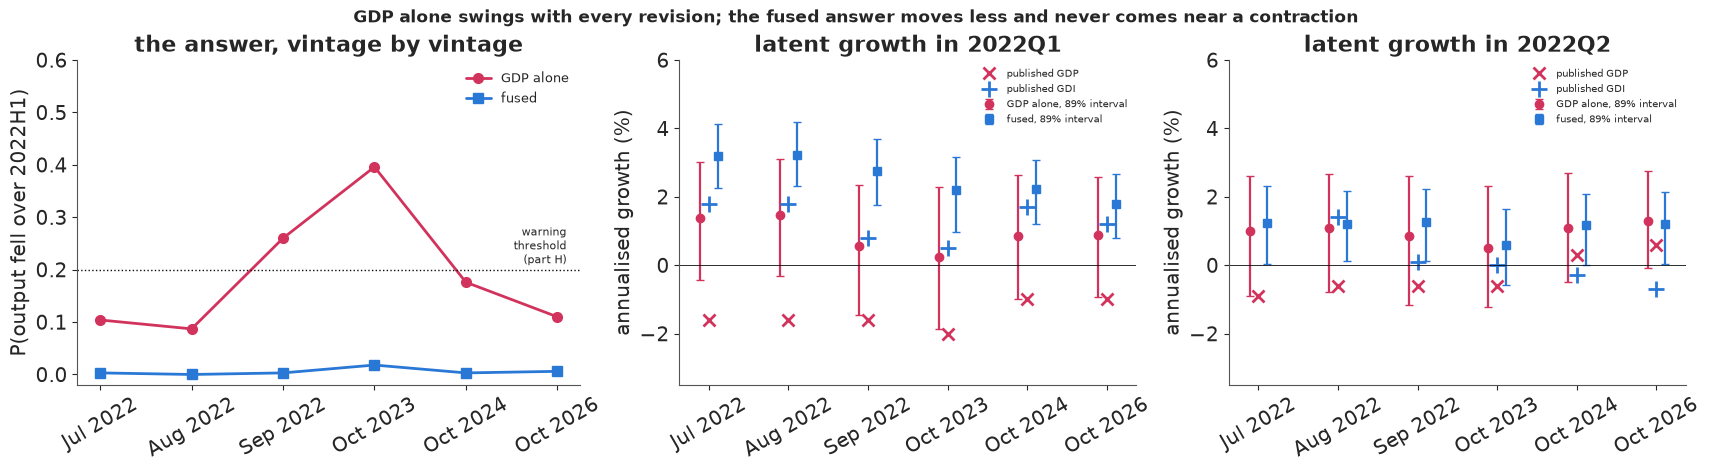

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), width_ratios=[1.1, 1, 1])
x = np.arange(len(VINTAGES))
ax = axes[0]
for kind, c, mk in (("GDP alone", RED, "o"), ("fused", BLUE, "s")):
    pr = replay[replay.model == kind]["P(H1 contraction)"].to_numpy()
    ax.plot(x, pr, marker=mk, color=c, lw=2, ms=7, label=kind)
ax.axhline(0.2, color=INK, ls=":", lw=1)
ax.text(5.1, 0.205, "warning\nthreshold\n(part H)", fontsize=8, va="bottom", ha="right")
ax.set_xticks(x, [VLABEL[v] for v in VINTAGES], rotation=30)
ax.set(ylabel="P(output fell over 2022H1)", ylim=(-0.02, 0.6), title="the answer, vintage by vintage")
ax.legend(fontsize=9)
for ax, qi, qn in ((axes[1], Q1, "2022Q1"), (axes[2], Q2, "2022Q2")):
    for j, (kind, c) in enumerate((("GDP alone", RED), ("fused", BLUE))):
        lo, hi = [], []
        for v in VINTAGES:
            gqv = FITS[f"{kind} {VLABEL[v]}"]["gq"][:, qi]
            lo.append(np.quantile(gqv, 0.055)); hi.append(np.quantile(gqv, 0.945))
        mid = [FITS[f"{kind} {VLABEL[v]}"]["gq"][:, qi].mean() for v in VINTAGES]
        ax.errorbar(x + (j - 0.5) * 0.22, mid, yerr=[np.subtract(mid, lo), np.subtract(hi, mid)], fmt="os"[j],
                    color=c, capsize=3, lw=1.6, label=f"{kind}, 89% interval")
    ax.plot(x, tab_a[f"GDP {qn[-2:]}"], "x", color=RED, ms=9, mew=2, label="published GDP")
    ax.plot(x, tab_a[f"GDI {qn[-2:]}"], "+", color=BLUE, ms=11, mew=2, label="published GDI")
    ax.axhline(0, color=INK, lw=0.6)
    ax.set_xticks(x, [VLABEL[v] for v in VINTAGES], rotation=30)
    ax.set(title=f"latent growth in {qn}", ylabel="annualised growth (%)", ylim=(-3.5, 6))
    ax.legend(fontsize=7, loc="upper right")
fig.suptitle("GDP alone swings with every revision; the fused answer moves less and never comes near a contraction",
             fontsize=12);

The left panel is the main result. With GDP alone, the probability that output fell over the first
half of 2022 is about 0.1 in July and August 2022, about 0.26 after the September 2022 annual update and
about 0.4 in October 2023, then back to 0.11-0.18 once the 2024 comprehensive revision lifted both
quarters. The September jump is the model's own fresh/mature switch at work: the GDP prints barely
changed (-1.6 and -0.6, as in August), but by the 245-day rule the first quarter stopped being fresh, so
the model dropped its revision noise and trusted the same -1.6 more. The size of that jump is a property
of our crude rule as much as of the data. October 2023 added a deeper first quarter (-2.0). The fused probability stays
below 0.02 at every vintage.

The middle and right panels show the same story for each quarter. The GDP-alone intervals are 3-4
points wide and follow the GDP crosses; the fused intervals are about half as wide for 2022Q1 and about a
third narrower for 2022Q2, and they sit above the GDP
crosses and, for the first quarter in the 2022-2023 vintages, above the GDI pluses too - the monthly
sensors pull them up. Across the six vintages the fused second-quarter estimate stays between about +0.6
and +1.3, while the GDP and GDI prints for that quarter cross zero in opposite directions.

But the fused first-quarter estimate *did* move, and in one direction: from about +3.2 in July 2022 to
about +1.8 in October 2026. The July 89% interval, roughly +2.3 to +4.1, does not contain the October 2026
posterior mean. We return to this in part G.

## F. Which sensor carries the answer?

Four more fits. The fused model without payrolls, as of July 2022. And GDP plus GDI with no monthly
sensors, as of August 2022 (when GDI first had a second-quarter reading), three times: with $\rho$ free,
and with $\rho$ fixed at 0 and at 0.8 through the `rho_free` / `rho_value` data switches.

In [19]:
fit("fused − payrolls", "2022-07-28", seed=RANDOM_SEED + 30,
    sensors=("gdp", "gdi", "indpro", "income_ex_transfers", "retail_sales"))
fit("GDP + GDI", "2022-08-25", seed=RANDOM_SEED + 31, sensors=("gdp", "gdi"))
for i, rho in enumerate((0.0, 0.8)):
    fit(f"GDP + GDI, rho={rho}", "2022-08-25", seed=RANDOM_SEED + 32 + i, sensors=("gdp", "gdi"), rho=rho)
f_gg = FITS["GDP + GDI"]
print(f"\nGDP + GDI, Aug 2022: posterior rho {f_gg['idata'].posterior['rho'].mean().item():+.2f} "
      f"± {f_gg['idata'].posterior['rho'].std().item():.2f} (prior sd 0.45); "
      f"fused, Jul 2022: {f_ar['idata'].posterior['rho'].mean().item():+.2f} ± "
      f"{f_ar['idata'].posterior['rho'].std().item():.2f}")
for key in ("GDP + GDI", "GDP + GDI, rho=0.0", "GDP + GDI, rho=0.8"):
    po = FITS[key]["idata"].posterior
    print(f"{key:<20} rho {float(po['rho'].mean()):+.2f}, sigma_P {float(po['sig_gdp'].mean()):.2f} "
          f"± {float(po['sig_gdp'].std()):.2f}, sigma_I {float(po['sig_gdi'].mean()):.2f} ± {float(po['sig_gdi'].std()):.2f}")

fused − payrolls, Jul 2022     9 s, divergences 0, max r_hat 1.005, min bulk ESS 1205 | 2022Q1 +1.98 ± 0.89, 2022Q2 +1.43 ± 1.03 | P(both < 0) 0.004, P(H1 contraction) 0.019


GDP + GDI, Aug 2022            6 s, divergences 0, max r_hat 1.001, min bulk ESS 1999 | 2022Q1 +1.54 ± 0.97, 2022Q2 +1.05 ± 1.01 | P(both < 0) 0.009, P(H1 contraction) 0.047


GDP + GDI, rho=0.0, Aug 2022   6 s, divergences 0, max r_hat 1.002, min bulk ESS 4275 | 2022Q1 +1.63 ± 0.94, 2022Q2 +1.09 ± 1.00 | P(both < 0) 0.017, P(H1 contraction) 0.047


GDP + GDI, rho=0.8, Aug 2022   7 s, divergences 0, max r_hat 1.008, min bulk ESS 261 | 2022Q1 +0.85 ± 1.24, 2022Q2 +0.57 ± 1.23 | P(both < 0) 0.122, P(H1 contraction) 0.248

GDP + GDI, Aug 2022: posterior rho -0.18 ± 0.32 (prior sd 0.45); fused, Jul 2022: +0.13 ± 0.18
GDP + GDI            rho -0.18, sigma_P 1.06 ± 0.29, sigma_I 1.64 ± 0.28
GDP + GDI, rho=0.0   rho +0.00, sigma_P 1.14 ± 0.24, sigma_I 1.71 ± 0.24
GDP + GDI, rho=0.8   rho +0.80, sigma_P 0.73 ± 0.63, sigma_I 2.52 ± 0.34


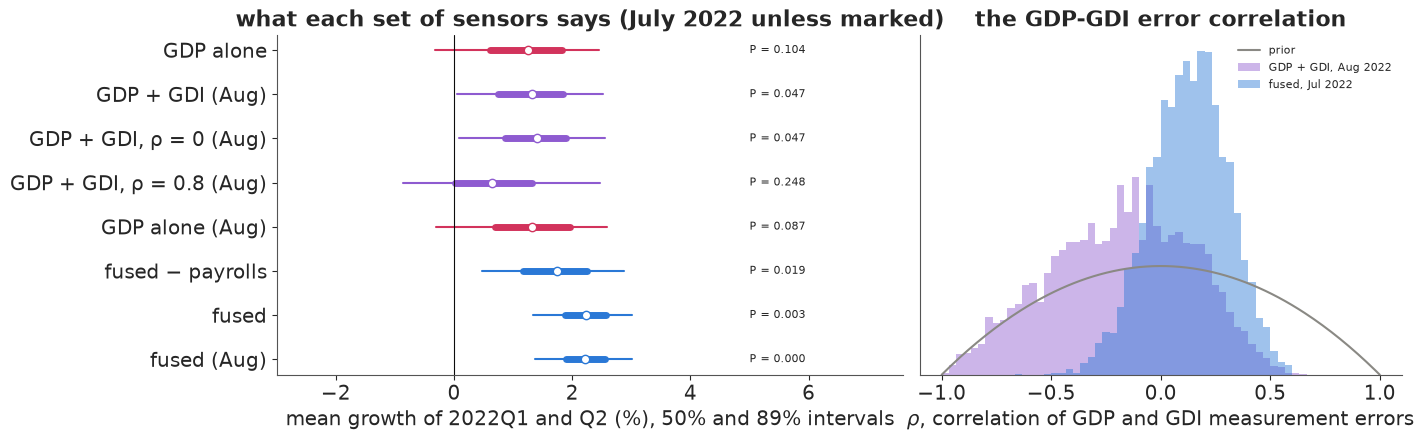

In [20]:
order = [("GDP alone", "GDP alone Jul 2022"), ("GDP + GDI (Aug)", "GDP + GDI"),
         ("GDP + GDI, ρ = 0 (Aug)", "GDP + GDI, rho=0.0"), ("GDP + GDI, ρ = 0.8 (Aug)", "GDP + GDI, rho=0.8"),
         ("GDP alone (Aug)", "GDP alone Aug 2022"), ("fused − payrolls", "fused − payrolls"),
         ("fused", "fused Jul 2022"), ("fused (Aug)", "fused Aug 2022")]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), width_ratios=[1.3, 1])
ax = axes[0]
for j, (lab, key) in enumerate(order):
    h1 = FITS[key]["gq"][:, [Q1, Q2]].mean(axis=1)
    lo, q25, med, q75, hi = np.quantile(h1, [0.055, 0.25, 0.5, 0.75, 0.945])
    c = BLUE if "fused" in lab else (PURPLE if "GDI" in lab else RED)
    ax.plot([lo, hi], [j, j], color=c, lw=1.5)
    ax.plot([q25, q75], [j, j], color=c, lw=5)
    ax.plot(med, j, "o", color="white", mec=c, ms=6)
    ax.text(5.0, j, f"P = {FITS[key]['h1']:.3f}", va="center", fontsize=8)
ax.axvline(0, color=INK, lw=0.8)
ax.set_yticks(range(len(order)), [o[0] for o in order])
ax.invert_yaxis()
ax.set(xlim=(-3, 7.6), xlabel="mean growth of 2022Q1 and Q2 (%), 50% and 89% intervals",
       title="what each set of sensors says (July 2022 unless marked)")
ax = axes[1]
xs = np.linspace(-1, 1, 200)
ax.plot(xs, stats.beta(2, 2).pdf((xs + 1) / 2) / 2, color=MUTED, lw=1.5, label="prior")
for f, c, lab in ((f_gg, PURPLE, "GDP + GDI, Aug 2022"), (f_ar, BLUE, "fused, Jul 2022")):
    ax.hist(f["idata"].posterior["rho"].values.ravel(), bins=60, range=(-1, 1), density=True, color=c,
            alpha=0.45, label=lab)
ax.set(xlabel=r"$\rho$, correlation of GDP and GDI measurement errors", yticks=[],
       title="the GDP-GDI error correlation");
ax.legend(fontsize=8);

Reading the forest from the top. **GDI matters once it exists**: in August, GDP alone puts the
probability of a first-half contraction at about 0.09, GDP plus GDI at about 0.05. **The error correlation
decides how much GDI counts.** With $\rho = 0$ the answer is the same as with $\rho$ free (0.05), but with
$\rho$ fixed at 0.8 it is about 0.25, worse than GDP alone. Two sensors with strongly correlated errors
should rarely disagree by much, yet GDP and GDI differ with an sd of about 2 points; with $\rho = 0.8$ the
model can only fit that gap by making GDI much noisier ($\sigma_I \approx 2.5$ against 1.6-1.7), so GDI
is discounted and the latent growth estimate moves back towards the GDP prints and widens.
The posterior for $\rho$ from GDP and GDI alone (right panel, purple) has a mean near -0.2 and an sd of
0.32 against the prior's 0.45: two series whose errors are both unobserved say little about how those
errors co-move. The fused model, which has an independent view of output from the monthly sensors,
narrows it to about 0.13 ± 0.18, a weak positive correlation.

**Payrolls set the level**: dropping them leaves the fused answer above zero (P about 0.02) but moves
first-quarter growth from about +3.2 to +2.0 and widens it (sd 0.9 instead of 0.6). **The monthly sensors
carry the July call**: before GDI's second-quarter number exists, the fused model is already as sure as it
is in August.

## G. Does the fused model fit, and was it right?

### Posterior predictive check on GDP and GDI

Simulate GDP and GDI readings from the latest-vintage fused fit (latent path draw plus the bivariate
measurement error) and compare with what was published.

In [21]:
f26 = FITS["fused Oct 2026"]
P26, gq26 = f26["P"], f26["gq"]
n_d = len(gq26)
z1, z2 = rng.standard_normal((2, n_d, NQ))
sp, si, rh = (P26[k][:, None] for k in ("sig_gdp", "sig_gdi", "rho"))
rep_gdp = gq26 + sp * z1
rep_gdi = gq26 + si * (rh * z1 + np.sqrt(1 - rh**2) * z2)
ok = ~np.isnan(q26["gdp"])
for s, rep in (("gdp", rep_gdp), ("gdi", rep_gdi)):
    lo, hi = np.quantile(rep, [0.055, 0.945], axis=0)
    inside = (q26[s] >= lo) & (q26[s] <= hi)
    pit = np.mean(rep < q26[s][None, :], axis=0)
    print(f"{s.upper()}: {inside[ok].mean():.0%} of {ok.sum()} quarters inside the 89% predictive interval; "
          f"PIT values: mean {pit[ok].mean():.2f}, sd {pit[ok].std():.2f} (uniform: 0.50, 0.29)")
gap = q26["gdp"] - q26["gdi"]
rep_gap = rep_gdp - rep_gdi
print(f"GDP - GDI gap: observed sd {np.nanstd(gap):.2f}; replicated sd {np.mean(np.std(rep_gap[:, ok], axis=1)):.2f} "
      f"(89%: {np.quantile(np.std(rep_gap[:, ok], axis=1), 0.055):.2f}-{np.quantile(np.std(rep_gap[:, ok], axis=1), 0.945):.2f})")

GDP: 92% of 37 quarters inside the 89% predictive interval; PIT values: mean 0.52, sd 0.26 (uniform: 0.50, 0.29)
GDI: 92% of 37 quarters inside the 89% predictive interval; PIT values: mean 0.49, sd 0.26 (uniform: 0.50, 0.29)
GDP - GDI gap: observed sd 2.06; replicated sd 2.08 (89%: 1.57-2.70)


### A held-out GDP print

A sharper check: what did the *other* sensors predict for GDP in 2022Q1 and Q2 on 28 July 2022? We refit
the fused model with those two GDP readings switched off (and with them GDI's first quarter, because the
likelihood reads GDI given GDP), so that only the four monthly sensors speak for the first half of 2022,
and ask what the fresh GDP prints, as published on 28 July, should have been (latent growth plus mature
and revision noise). The tail probability of the published print is computed for each posterior draw
exactly, from the normal measurement model, and then averaged; counting predictive draws below the print
would rest on a handful of draws.

In [22]:
f_ho = fit("fused, GDP H1 hidden", "2022-07-28", seed=RANDOM_SEED + 40, hide=("2022-01-01", "2022-04-01"))
Pho = f_ho["P"]
sd_fresh = np.sqrt(Pho["sig_gdp"] ** 2 + TAU["gdp"] ** 2)
for qi, qn in ((Q1, "2022Q1"), (Q2, "2022Q2")):
    pred = f_ho["gq"][:, qi] + sd_fresh * rng.standard_normal(len(sd_fresh))
    p_low = stats.norm.cdf((q0["gdp"][qi] - f_ho["gq"][:, qi]) / sd_fresh)   # exact per draw, then averaged
    print(f"{qn}: predicted GDP print {pred.mean():+.2f}, 89% interval {np.quantile(pred, 0.055):+.2f} to "
          f"{np.quantile(pred, 0.945):+.2f}; published {q0['gdp'][qi]:+.1f}, "
          f"P(print this low or lower) = {p_low.mean():.4f}")

fused, GDP H1 hidden, Jul 2022  11 s, divergences 1, max r_hat 1.039, min bulk ESS 141 | 2022Q1 +4.32 ± 0.90, 2022Q2 +2.14 ± 0.90 | P(both < 0) 0.000, P(H1 contraction) 0.000
2022Q1: predicted GDP print +4.33, 89% interval +1.05 to +7.61; published -1.6, P(print this low or lower) = 0.0028
2022Q2: predicted GDP print +2.11, 89% interval -1.24 to +5.46; published -0.9, P(print this low or lower) = 0.0740


### Scoring July 2022 against October 2026

GDP alone 2022Q1: July 2022 89% interval -0.43 to +3.02; Oct 2026 posterior mean +0.88 (inside); Oct 2026 mean of GDP and GDI +0.10 (inside)
GDP alone 2022Q2: July 2022 89% interval -0.89 to +2.62; Oct 2026 posterior mean +1.29 (inside); Oct 2026 mean of GDP and GDI -0.05 (inside)
fused     2022Q1: July 2022 89% interval +2.27 to +4.12; Oct 2026 posterior mean +1.80 (OUTSIDE); Oct 2026 mean of GDP and GDI +0.10 (OUTSIDE)
fused     2022Q2: July 2022 89% interval +0.04 to +2.31; Oct 2026 posterior mean +1.20 (inside); Oct 2026 mean of GDP and GDI -0.05 (OUTSIDE)


fused − payrolls Oct 2026      9 s, divergences 0, max r_hat 1.005, min bulk ESS 1000 | 2022Q1 +0.91 ± 0.78, 2022Q2 +0.82 ± 0.81 | P(both < 0) 0.028, P(H1 contraction) 0.067


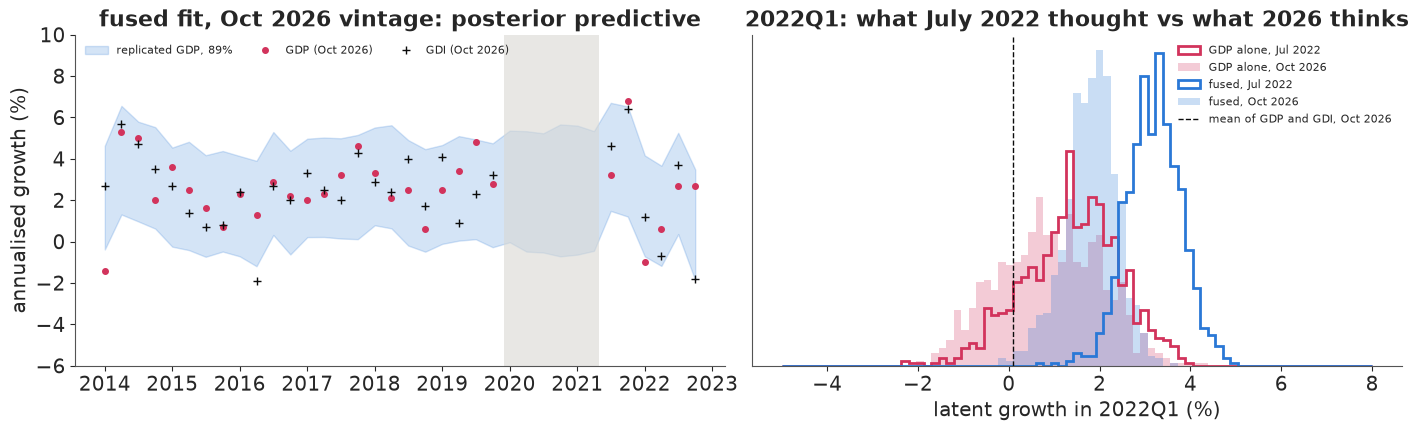

In [23]:
for kind in ("GDP alone", "fused"):
    fj, fo = FITS[f"{kind} Jul 2022"], FITS[f"{kind} Oct 2026"]
    for qi, qn in ((Q1, "2022Q1"), (Q2, "2022Q2")):
        lo, hi = np.quantile(fj["gq"][:, qi], [0.055, 0.945])
        later = fo["gq"][:, qi].mean()
        avg_pub = (q26["gdp"][qi] + q26["gdi"][qi]) / 2
        print(f"{kind:<9} {qn}: July 2022 89% interval {lo:+.2f} to {hi:+.2f}; Oct 2026 posterior mean "
              f"{later:+.2f} ({'inside' if lo <= later <= hi else 'OUTSIDE'}); Oct 2026 mean of GDP and GDI "
              f"{avg_pub:+.2f} ({'inside' if lo <= avg_pub <= hi else 'OUTSIDE'})")
f_np26 = fit("fused − payrolls Oct 2026", "2026-10-01", seed=RANDOM_SEED + 41,
             sensors=("gdp", "gdi", "indpro", "income_ex_transfers", "retail_sales"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axes[0]
qwin = QUARTERS >= "2014-01-01"
lo, hi = np.quantile(rep_gdp, [0.055, 0.945], axis=0)
ax.fill_between(QUARTERS[qwin], lo[qwin], hi[qwin], color=BLUE, alpha=0.2, label="replicated GDP, 89%")
ax.plot(QUARTERS[qwin], q26["gdp"][qwin], "o", color=RED, ms=4, label="GDP (Oct 2026)")
ax.plot(QUARTERS[qwin], q26["gdi"][qwin], "+", color=INK, ms=6, label="GDI (Oct 2026)")
ax.axvspan(pd.Timestamp("2019-12-01"), pd.Timestamp("2021-05-01"), color=LIGHT, alpha=0.6, lw=0)
ax.set(ylim=(-6, 10), ylabel="annualised growth (%)", title="fused fit, Oct 2026 vintage: posterior predictive")
ax.legend(fontsize=8, ncols=3, loc="upper left")
ax = axes[1]
bins = np.linspace(-5, 8, 80)
for kind, c in (("GDP alone", RED), ("fused", BLUE)):
    ax.hist(FITS[f"{kind} Jul 2022"]["gq"][:, Q1], bins=bins, density=True, histtype="step", color=c, lw=2,
            label=f"{kind}, Jul 2022")
    ax.hist(FITS[f"{kind} Oct 2026"]["gq"][:, Q1], bins=bins, density=True, color=c, alpha=0.25,
            label=f"{kind}, Oct 2026")
ax.axvline((q26["gdp"][Q1] + q26["gdi"][Q1]) / 2, color=INK, ls="--", lw=1, label="mean of GDP and GDI, Oct 2026")
ax.set(xlabel="latent growth in 2022Q1 (%)", yticks=[], title="2022Q1: what July 2022 thought vs what 2026 thinks")
ax.legend(fontsize=8);

**The fit.** Over 2012-2022 (October 2026 vintage) the fused model's 89% predictive intervals contain 34
of 37 published GDP growth rates and 34 of 37 GDI ones, and the PIT values have the right centre with a
slightly small spread (0.26 against 0.29 for a uniform), so the predictive intervals are, if anything, a
little wide. The spread of the GDP-GDI gap is reproduced (2.06 observed, 2.08 replicated), which is what
$\rho$, $\sigma_P$ and $\sigma_I$ must jointly get right.

**The held-out prints.** With their own GDP readings hidden, the monthly sensors as published in July 2022
put first-quarter growth at about +4.3 and expected the GDP print to be about +4.3 too (89%: +1.1 to
+7.6). The probability of a print of -1.6 or lower, computed exactly for each posterior draw and averaged,
is about 0.003, roughly one chance in 350; for the second-quarter -0.9 it is about 0.07. This fit mixed
less well than the others - one divergence, r-hat up to about 1.04, bulk ESS about 140 - so read the
first number as "a few in a thousand" rather than to its last digit. By the model's own account, then,
the July 2022 data contained a conflict between GDP and the monthly sensors that its noise model does not
expect. The fused posterior in part D resolved it largely in favour of the monthly sensors (+3.2 for the
first quarter, much nearer their +4.3 than GDP's -1.6), with an interval only 2 points wide; the held-out
check is the warning that this precision rests on a disagreement the model calls a 1-in-350 event.

**The score.** GDP alone in July 2022 was vague and therefore not wrong: its intervals contain both the
October 2026 posterior and the October 2026 GDP-GDI average. The fused model in July 2022 was right about
the sign but **overconfident about the size**: its first-quarter interval (+2.3 to +4.1) misses both the
October 2026 fused posterior (+1.8) and the GDP-GDI average (+0.1), and its second-quarter interval misses
the average narrowly. Hindsight sided partly with GDP: the monthly sensors that drove the July estimate
were revised down (industrial production's first half from 5.1% to 0.9%, real income from +0.6% to -3.5%),
and the model had treated them as final. The remaining gap between the 2026 fused estimate and the
GDP-GDI average is mostly payrolls, which grew at about 3.5% a year in the first half at every vintage
(3.4-3.7): without them,
the October 2026 fit puts first-quarter growth at about +0.9 ± 0.8 instead of +1.8 ± 0.6. Fusion shrinks
variance; it cannot remove a bias that the sensor models share.

## H. Should a forecaster have called a recession?

Suppose a forecaster must decide, at each vintage, whether to issue a **recession warning** for the first
half of 2022. A missed contraction is costly (clients are not hedged), a false warning less so; say
a miss costs four times a false alarm. Warning when $P(\text{contraction}) > c_{\rm FA}/(c_{\rm FA} +
c_{\rm miss}) = 1/5$ minimises expected cost.

In [24]:
dec = replay.pivot(index="vintage", columns="model", values="P(H1 contraction)").loc[[VLABEL[v] for v in VINTAGES]]
naive = ["warn" if (tab_a.loc[VLABEL[v], "GDP Q1"] < 0) and (tab_a.loc[VLABEL[v], "GDP Q2"] < 0) else "no"
         for v in VINTAGES]
dec["two negative GDP prints"] = naive
for kind in ("GDP alone", "fused"):
    dec[f"{kind}: decision"] = np.where(dec[kind] > 0.2, "warn", "no")
print(dec.round(3).to_string())
print(f"\nnotebook ran {time.time() - T_START:.0f} s")

model     GDP alone  fused two negative GDP prints GDP alone: decision fused: decision
vintage                                                                               
Jul 2022      0.104  0.003                    warn                  no              no
Aug 2022      0.087  0.000                    warn                  no              no
Sep 2022      0.260  0.003                    warn                warn              no
Oct 2023      0.396  0.018                    warn                warn              no
Oct 2024      0.176  0.003                      no                  no              no
Oct 2026      0.110  0.006                      no                  no              no

notebook ran 212 s


The two-quarter rule, applied to GDP as published, says "warn" at every vintage until October 2024.
GDP read as a noisy sensor says "no" in July and August 2022, "warn" after the September 2022 and
2023 updates, and "no" again from October 2024 - the decision flips twice because one noisy sensor is all
it has. The fused model says "no" at every vintage, and that call held: the NBER never dated a recession,
and in the October 2026 vintage GDP and GDI average to roughly zero growth over the half year, not a
contraction. The decision-relevant gain from fusion is not a sharper number - part G showed the fused
number was too high - but a **stable** answer, robust to which sensor gets revised next.

## Summary

* **Six sensors, one latent path.** Monthly output growth as an AR(1), quarterly GDP and GDI as
  Mariano-Murasawa weighted sums of it with correlated errors, and four monthly indicators as affine noisy
  readings. The ragged edge and the masked pandemic months are just absent rows; GDP alone, GDP + GDI and
  the fused model are one compiled model with different sensors switched on.
* **Integrating the path out** with banded precision matrices (one 132 × 132 Cholesky per gradient)
  matched a brute-force multivariate normal on 508 readings to every printed digit. In prototypes not
  shown here, sampling the path directly gave r-hat 1.05-1.14 and ESS 20-90; the integrated fits ran in 6-12 seconds each with
  r-hat of 1.00-1.01 and almost no divergences, the fit with held-out GDP prints being the worst (r-hat
  about 1.04).
* **Revision noise is large.** A fresh GDP growth rate moved by 1.4 points (root mean square) on its way
  to the 2026 vintage, GDI by 1.5, over 22 quarters of 2014-2019. Monthly sensors were revised too:
  industrial production's first half of 2022 went from 5.1% to 0.9%.
* **GDP alone, read as a noisy sensor, never said "contraction" with confidence** - P(H1 contraction)
  about 0.1 in July 2022 against a prior 0.19 - but its answer swung between about 0.09 and 0.4 as GDP
  was revised, and it leans on the prior for GDP's own noise.
* **The naive fused model was confidently wrong about the level** (2022Q1 at +4.8 ± 0.55): payrolls with
  independent errors became a near-perfect reading of a smooth economy. A residual check flagged retail
  sales (with a hint of the same in real income) but not payrolls, whose residuals the bent path had
  made white; the 3-sd GDP misfit and the expanded model (payroll error persistence 0.96, interval 0.90-0.99) exposed it.
* **Fusion changed the answer and kept it stable**: P(H1 contraction) below 0.02 at all six vintages,
  against 0.09-0.4 for GDP alone, with intervals about half as wide for 2022Q1 and a third narrower
  for 2022Q2. But the July 2022 fused interval for 2022Q1 (+2.3 to +4.1) missed the 2026 estimate (+1.8): the monthly sensors it treated as final were
  revised down, and a held-out check had already put the GDP-monthly conflict at about 1 in 350. Most of
  the remaining gap to the GDP-GDI average (+0.1) is payrolls.
* **The GDP-GDI error correlation is weakly identified** from those two series alone (posterior sd 0.32
  against a prior 0.45) and it matters: fixing it at 0.8 instead of 0 raised the August 2022 contraction
  probability from about 0.05 to 0.25. The monthly sensors pin it to about 0.13 ± 0.18.
* **Decision**: with a miss four times as costly as a false alarm, the fused model never warns; GDP alone
  warns at two of six vintages; the two-quarter rule warns at four. No recession was declared.

## Try it yourself

1. **A recession regime.** Replace the AR(1) mean by a two-state Markov-switching mean (expansion and
   contraction, as in Chauvet & Piger 2008), summed out with a forward filter as in E24. The integrated
   likelihood no longer applies exactly; sample the path non-centred or condition on the regime path. Does
   P(contraction regime in 2022H1) differ from P(H1 contraction) here, and is the regime model's prior
   probability of a recession more sensible?
2. **Revisions for every sensor.** The monthly sensors are treated as final. Measure the revision noise of
   payrolls and real income from ALFRED vintages (as we did for GDP and GDI) and add it for readings less
   than a year old. Does the July 2022 fused interval for 2022Q1 now contain the 2026 estimate?
3. **A drifting long-run mean and a breaking sensor.** Let $\mu$ follow a slow random walk by year
   (Antolin-Diaz, Drechsel & Petrella 2017) and let the payroll intercept $a_{\rm pay}$ change after the
   pandemic. Which of the two absorbs 2022's "jobs without output", and what happens to the fused level?
   While you are there, let the payroll error be a random walk ($\psi = 1$, payrolls informing only
   changes in growth) instead of an AR(1) capped at 0.99, and see how much of the payroll level effect
   survives.